# Trabalho Prático 2 - Recuperação de Informação (SCC0282)

**Integrantes do grupo:** Ana Paula de Abreu Batista - 12688424 e Italo Carlos Martins Bresciani - 15461782

**Dataset:** NFCorpus (versão do benchmark BEIR)

Este notebook implementa e avalia um sistema de Recuperação de Informação que combina **busca lexical** (BM25 sobre um índice invertido construído do zero) e **busca semântica** (embeddings densos de um bi-encoder), com **tolerância a erros** de digitação, **fusão de rankings** (RRF), **reranking** com cross-encoder e **geração de respostas com RAG**. O pipeline completo é:

`documentos → pré-processamento e indexação → recuperação lexical + recuperação semântica → busca híbrida → reranking → seleção de contexto → LLM → resposta`

As seções seguem a numeração dos requisitos do enunciado (Requisito 1 a 15). Cada seção traz o código, os resultados e, logo depois, a análise correspondente.

**Protocolo experimental (vale para o notebook inteiro):**
- toda escolha de configuração (pré-processamento, modelo de embeddings, parâmetros da correção ortográfica, $k$ do RRF, modelo de reranking) é feita no conjunto `dev`;
- o conjunto `test` é usado apenas na avaliação final, com as configurações já fixadas;
- cada comparação altera somente o componente investigado.

## Configuração do ambiente

Instalação das bibliotecas (em ambiente local, o equivalente é `pip install -r requirements.txt`): `nltk` (stopwords e stemming), `sentence-transformers` (bi-encoder e cross-encoder), `llama-cpp-python` (execução local da LLM), `ir-measures` (conferência das métricas), além de `numpy`, `pandas` e `matplotlib`.

In [1]:
%pip install -q --disable-pip-version-check numpy pandas nltk matplotlib ir-measures sentence-transformers huggingface_hub
%pip install -q --disable-pip-version-check --prefer-binary llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import re
import csv
import json
import math
import time
import heapq
import random
import zipfile
import urllib.request
from collections import Counter
from functools import lru_cache
from importlib.metadata import version

import numpy as np
import pandas as pd
import torch

# Registro das versões usadas na execução (reprodutibilidade)
print(f"Python {sys.version.split()[0]}")
for pacote in ['numpy', 'pandas', 'nltk', 'torch', 'transformers', 'sentence-transformers',
               'llama-cpp-python', 'ir-measures', 'matplotlib']:
    print(f"{pacote}: {version(pacote)}")

# Hardware: os modelos neurais usam GPU se houver; caso contrário, CPU
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
try:
    cpu = next(l.split(':')[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name'))
except (OSError, StopIteration):
    cpu = 'não identificada'
print(f"\nDispositivo: {DEVICE} | CPU: {cpu} | threads: {os.cpu_count()}")

pd.set_option('display.max_colwidth', 70)
pd.set_option('display.width', 200)

Python 3.12.3
numpy: 2.5.4
pandas: 3.1.1
nltk: 3.10.4
torch: 2.15.0+cpu
transformers: 5.23.0
sentence-transformers: 6.3.0
llama-cpp-python: 0.3.36
ir-measures: 0.4.3
matplotlib: 3.11.2

Dispositivo: cpu | CPU: 13th Gen Intel(R) Core(TM) i5-1334U | threads: 12


Todos os parâmetros dos experimentos ficam reunidos na célula abaixo. Os valores marcados como "escolhido no dev" são definidos mais adiante, pelas células de ajuste.

As etapas pesadas (embeddings dos documentos, scores do cross-encoder e respostas da LLM) são calculadas na primeira execução e gravadas em disco; nas execuções seguintes são apenas carregadas. Os tempos reportados são sempre os medidos no momento do cálculo. O README explica como refazer tudo do zero.

In [3]:
SEED = 42                      # semente usada em todos os sorteios
K = 10                         # corte das métricas (P@10, R@10, AP@10 e NDCG@10)
TOP_N = 100                    # tamanho dos rankings salvos e nº de documentos de cada sistema fundidos pelo RRF
TOP_RERANK = 50                # nº de documentos do ranking híbrido reordenados pelo cross-encoder
TOP_CONTEXTO = 5               # nº de documentos enviados à LLM no RAG

# BM25: valores usuais (padrão do Lucene/Elasticsearch, dentro da faixa recomendada por Manning et al.);
# como não foram alterados, não há ajuste desses parâmetros
BM25_K1 = 1.2
BM25_B = 0.75

VALORES_K_RRF = [10, 60, 100]  # valores de k do RRF avaliados no dev

# Pastas: 'resultados' é entregue; as demais guardam arquivos grandes que o notebook gera de novo se faltarem
DIR_DADOS = 'dados'            # coleção NFCorpus
DIR_ARTEFATOS = 'artefatos'    # embeddings dos documentos e scores do cross-encoder
DIR_MODELOS = 'modelos'        # arquivo da LLM
DIR_RESULTADOS = 'resultados'  # CSVs padronizados e gráficos
for pasta in [DIR_DADOS, DIR_ARTEFATOS, DIR_MODELOS, DIR_RESULTADOS]:
    os.makedirs(pasta, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
_ = torch.manual_seed(SEED)

## Dataset e splits

Usamos o arquivo oficial do BEIR, que traz `corpus.jsonl`, `queries.jsonl` e os qrels de cada split. As consultas de cada conjunto são as que possuem julgamentos no respectivo arquivo (`qrels/dev.tsv` e `qrels/test.tsv`).

Cada documento é representado pela concatenação `title + " " + text`. Essa mesma representação é usada em todos os sistemas (lexical, semântico e reranking) e também no contexto do RAG.

In [4]:
URL_NFCORPUS = 'https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/nfcorpus.zip'
DIR_NFCORPUS = os.path.join(DIR_DADOS, 'nfcorpus')
ARQUIVOS = ['nfcorpus/corpus.jsonl', 'nfcorpus/queries.jsonl', 'nfcorpus/qrels/dev.tsv', 'nfcorpus/qrels/test.tsv']

# Baixa e extrai a coleção apenas na primeira execução
if not all(os.path.exists(os.path.join(DIR_DADOS, a)) for a in ARQUIVOS):
    caminho_zip = os.path.join(DIR_DADOS, 'nfcorpus.zip')
    if not os.path.exists(caminho_zip):
        urllib.request.urlretrieve(URL_NFCORPUS, caminho_zip)
    with zipfile.ZipFile(caminho_zip) as z:
        for arquivo in ARQUIVOS:
            z.extract(arquivo, DIR_DADOS)

# Documentos: doc_id -> título e texto completo (título + texto)
titulos, corpus = {}, {}
with open(os.path.join(DIR_NFCORPUS, 'corpus.jsonl'), encoding='utf-8') as f:
    for linha in f:
        d = json.loads(linha)
        titulos[d['_id']] = d['title']
        corpus[d['_id']] = d['title'] + ' ' + d['text']
doc_ids = list(corpus)                       # ordem do arquivo; a posição na lista é o identificador interno
textos_docs = [corpus[d] for d in doc_ids]

# Consultas: query_id -> texto (o arquivo contém as consultas de todos os splits)
consultas = {}
with open(os.path.join(DIR_NFCORPUS, 'queries.jsonl'), encoding='utf-8') as f:
    for linha in f:
        q = json.loads(linha)
        consultas[q['_id']] = q['text']

def carregar_qrels(caminho):
    """Lê um arquivo de qrels e devolve {query_id: {doc_id: grau de relevância}}."""
    qrels = {}
    with open(caminho, encoding='utf-8') as f:
        leitor = csv.reader(f, delimiter='\t')
        next(leitor)                         # cabeçalho: query-id, corpus-id, score
        for query_id, doc_id, grau in leitor:
            qrels.setdefault(query_id, {})[doc_id] = int(grau)
    return qrels

qrels_dev = carregar_qrels(os.path.join(DIR_NFCORPUS, 'qrels', 'dev.tsv'))
qrels_test = carregar_qrels(os.path.join(DIR_NFCORPUS, 'qrels', 'test.tsv'))
ids_dev = sorted(qrels_dev)                  # consultas de cada split = as que têm julgamentos
ids_test = sorted(qrels_test)

print(f"Documentos: {len(corpus)} | consultas no arquivo: {len(consultas)}")
for nome, qrels in [('dev', qrels_dev), ('test', qrels_test)]:
    graus = Counter(g for docs in qrels.values() for g in docs.values())
    media_rel = np.mean([sum(g > 0 for g in docs.values()) for docs in qrels.values()])
    print(f"{nome}: {len(qrels)} consultas | {sum(graus.values())} julgamentos | graus: {dict(sorted(graus.items()))} "
          f"| média de relevantes por consulta: {media_rel:.1f}")
palavras_test = [len(consultas[q].split()) for q in ids_test]
print(f"Consultas do test: {np.mean(palavras_test):.1f} palavras em média | {sum(n == 1 for n in palavras_test)} com uma única palavra")
print(f"\nExemplo de documento ({doc_ids[0]}): {textos_docs[0][:160]}...")
print(f"Exemplo de consulta ({ids_test[0]}): {consultas[ids_test[0]]}")

Documentos: 3633 | consultas no arquivo: 3237
dev: 324 consultas | 11385 julgamentos | graus: {1: 10864, 2: 521} | média de relevantes por consulta: 35.1
test: 323 consultas | 12334 julgamentos | graus: {1: 11758, 2: 576} | média de relevantes por consulta: 38.2
Consultas do test: 3.3 palavras em média | 103 com uma única palavra

Exemplo de documento (MED-10): Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland Recent studies have suggested that statins, an established drug group in the preve...
Exemplo de consulta (PLAIN-1008): deafness


## Métricas de avaliação (usadas em todas as etapas)

As métricas do Requisito 6 são definidas aqui porque já são necessárias nos ajustes feitos no `dev`. Todas são calculadas por consulta, sobre as 10 primeiras posições do ranking:

- **Precision@10:** fração dos 10 primeiros documentos que são relevantes.
- **Recall@10:** relevantes entre os 10 primeiros, dividido pelo total de relevantes da consulta nos qrels.
- **AP@10:** soma de Precision@k nas posições $k \le 10$ que contêm documento relevante, dividida pelo total de relevantes da consulta nos qrels (convenção do `trec_eval`). O **MAP@10** é a média de AP@10 entre as consultas.
- **NDCG@10:** $DCG@10 = \sum_{i=1}^{10} \frac{g_i}{\log_2(i+1)}$, com ganho linear ($g_i$ = grau de relevância do documento na posição $i$), dividido pelo DCG do ranking ideal, montado com todos os julgamentos da consulta.

Para P@10, R@10 e AP@10, é relevante todo documento com grau maior que zero. O NDCG@10 preserva os graus (1 e 2). Documentos sem julgamento contam como não relevantes (grau 0).

In [5]:
def metricas_consulta(ranking, relevancias, k=K):
    """Calcula P@k, R@k, AP@k e NDCG@k de uma consulta.
    ranking: lista de doc_ids em ordem decrescente de score; relevancias: {doc_id: grau} dos qrels."""
    topo = ranking[:k]
    total_relevantes = sum(1 for g in relevancias.values() if g > 0)

    acertos, soma_precisoes, dcg = 0, 0.0, 0.0
    for pos, doc_id in enumerate(topo, start=1):
        grau = relevancias.get(doc_id, 0)
        if grau > 0:
            acertos += 1
            soma_precisoes += acertos / pos          # Precision@pos, somada só nas posições com relevante
        dcg += grau / math.log2(pos + 1)             # ganho linear com desconto logarítmico

    # Ranking ideal: os maiores graus da consulta, considerando todos os julgamentos
    graus_ideais = sorted(relevancias.values(), reverse=True)[:k]
    idcg = sum(g / math.log2(pos + 1) for pos, g in enumerate(graus_ideais, start=1))

    return {
        'P10': acertos / k,
        'R10': acertos / total_relevantes if total_relevantes else 0.0,
        'AP10': soma_precisoes / total_relevantes if total_relevantes else 0.0,
        'NDCG10': dcg / idcg if idcg > 0 else 0.0,
    }

def avaliar(rankings, qrels, ids_consultas):
    """Avalia um sistema: rankings = {query_id: [(doc_id, score), ...]}. Devolve um DataFrame com uma linha por consulta."""
    linhas = []
    for q in ids_consultas:
        ordem = [doc_id for doc_id, _ in rankings[q]]
        linhas.append({'query_id': q, **metricas_consulta(ordem, qrels[q])})
    return pd.DataFrame(linhas)

METRICAS = ['P10', 'R10', 'AP10', 'NDCG10']

# Teste rápido com um ranking pequeno, conferido à mão:
# relevantes nas posições 1 (grau 2) e 3 (grau 1); a consulta tem 3 relevantes no total
exemplo = metricas_consulta(['a', 'x', 'b'], {'a': 2, 'b': 1, 'c': 1}, k=3)
print(exemplo)   # P = 2/3; R = 2/3; AP = (1/1 + 2/3)/3 = 0,556; NDCG = (2 + 0,5)/(2 + 0,631 + 0,5) = 0,798

{'P10': 0.6666666666666666, 'R10': 0.6666666666666666, 'AP10': 0.5555555555555555, 'NDCG10': 0.7984848580994974}


## Requisito 1: Pré-processamento

Reaproveitamos as funções do Trabalho Prático 1, com a biblioteca `nltk`:

1. **Normalização:** conversão para letras minúsculas.
2. **Tokenização:** `RegexpTokenizer(r'\w+')`, que separa o texto em sequências de letras e dígitos e descarta a pontuação.
3. **Remoção de stopwords:** lista de stopwords do inglês do NLTK.
4. **Stemming:** algoritmo de Porter (`PorterStemmer`).

Documentos e consultas passam exatamente pelas mesmas etapas, para que os termos da consulta casem com os termos do índice. Não usamos lematização: ela exigiria etiquetagem morfossintática, e o stemming já agrupa as variantes morfológicas mais comuns.

As etapas 3 e 4 são opcionais na função. Quais delas usar é decidido no conjunto `dev` (ao final do Requisito 3), comparando as quatro combinações possíveis, como no TP1.

In [6]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from nltk.stem import PorterStemmer

nltk.download('stopwords', quiet=True)

tokenizador = RegexpTokenizer(r'\w+')        # tokeniza removendo a pontuação
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def tokenizar(texto):
    """Normalização (minúsculas) + tokenização. É a forma dos termos 'antes do stemming'."""
    return tokenizador.tokenize(str(texto).lower())

@lru_cache(maxsize=None)
def radical(token):
    """Stemming de Porter com cache: cada palavra distinta do vocabulário é processada uma única vez."""
    return stemmer.stem(token)

def preprocessar(texto, remover_stopwords=True, usar_stemming=True):
    tokens = tokenizar(texto)
    if remover_stopwords:
        tokens = [t for t in tokens if t not in stop_words]
    if usar_stemming:
        tokens = [radical(t) for t in tokens]
    return tokens

# As quatro configurações comparadas no dev
CONFIGS_PREPROC = {
    'basico':    dict(remover_stopwords=False, usar_stemming=False),
    'stopwords': dict(remover_stopwords=True,  usar_stemming=False),
    'stemming':  dict(remover_stopwords=False, usar_stemming=True),
    'ambos':     dict(remover_stopwords=True,  usar_stemming=True),
}

exemplo = consultas['PLAIN-2430']
print("Consulta original:", exemplo)
for nome, cfg in CONFIGS_PREPROC.items():
    print(f"  {nome:<10} {preprocessar(exemplo, **cfg)}")

Consulta original: Preventing Brain Loss with B Vitamins?
  basico     ['preventing', 'brain', 'loss', 'with', 'b', 'vitamins']
  stopwords  ['preventing', 'brain', 'loss', 'b', 'vitamins']
  stemming   ['prevent', 'brain', 'loss', 'with', 'b', 'vitamin']
  ambos      ['prevent', 'brain', 'loss', 'b', 'vitamin']


## Requisito 2: Índice invertido (implementado do zero)

O índice usa apenas estruturas genéricas do Python:

- **Dicionário de termos:** um `dict` que mapeia cada termo à sua *posting list*.
- **Posting list:** lista de pares `(doc_idx, tf)`, em que `doc_idx` é a posição do documento na coleção e `tf` é a frequência do termo no documento. Como os documentos são inseridos em ordem, cada lista fica ordenada por `doc_idx`.
- **DF:** não precisa ser armazenado à parte, pois é o comprimento da posting list.
- **Tamanho dos documentos:** lista com o número de tokens de cada documento.
- **Estatísticas globais:** número de documentos $N$ e tamanho médio dos documentos, usados pelo BM25.

A construção percorre a coleção uma única vez. Na consulta, só as posting lists dos termos da consulta são lidas.

In [7]:
class IndiceInvertido:
    def __init__(self, doc_ids, docs_tokens):
        self.doc_ids = list(doc_ids)                         # doc_idx -> doc_id original
        self.N = len(self.doc_ids)                           # nº de documentos da coleção
        self.tam_docs = [len(tokens) for tokens in docs_tokens]
        self.tam_medio = sum(self.tam_docs) / self.N         # tamanho médio dos documentos (em tokens)
        self.postings = {}                                   # termo -> [(doc_idx, tf), ...]
        for doc_idx, tokens in enumerate(docs_tokens):
            for termo, tf in Counter(tokens).items():        # tf = nº de ocorrências do termo no documento
                self.postings.setdefault(termo, []).append((doc_idx, tf))

    def df(self, termo):
        """Document frequency: nº de documentos que contêm o termo."""
        return len(self.postings.get(termo, ()))

    @property
    def num_termos(self):
        return len(self.postings)

    @property
    def num_postings(self):
        return sum(len(lista) for lista in self.postings.values())

# Demonstração em uma coleção de três documentos
mini = IndiceInvertido(['d1', 'd2', 'd3'], [preprocessar(t) for t in
                       ['Milk and bone health', 'Bones need calcium; milk has calcium', 'Green tea and hydration']])
for termo in ['milk', 'bone', 'calcium', 'tea']:
    print(f"{termo:<8} df={mini.df(termo)}  postings={mini.postings[termo]}")
print("tamanhos:", mini.tam_docs, "| tamanho médio:", round(mini.tam_medio, 2))

milk     df=2  postings=[(0, 1), (1, 1)]
bone     df=2  postings=[(0, 1), (1, 1)]
calcium  df=1  postings=[(1, 2)]
tea      df=1  postings=[(2, 1)]
tamanhos: [3, 5, 3] | tamanho médio: 3.67


## Requisito 3: Busca lexical (BM25)

**Escolha do baseline:** BM25. Justificativa: no TP1 ele teve MAP maior que o Modelo Vetorial nas quatro configurações de pré-processamento, e ele trata explicitamente dois efeitos importantes nesta coleção, a saturação da frequência do termo ($k_1$) e a normalização pelo tamanho do documento ($b$). Também é o baseline lexical usado no benchmark BEIR. O mesmo modelo é mantido em todos os experimentos seguintes.

A fórmula é a mesma implementada no TP1 (Robertson & Zaragoza, com o IDF na variante do Lucene, que nunca é negativo):

$$\text{score}(q,d) = \sum_{t \in q} IDF(t) \cdot \frac{f_{t,d}\,(k_1+1)}{f_{t,d} + k_1\left(1 - b + b\cdot\frac{|d|}{avgdl}\right)} \qquad IDF(t) = \log\left(\frac{N - df_t + 0.5}{df_t + 0.5} + 1\right)$$

A diferença em relação ao TP1 está na forma de calcular. Lá, o score era calculado para todos os documentos da coleção. Aqui, a busca é **termo a termo** sobre o índice invertido: para cada termo da consulta, percorremos somente a sua posting list e somamos a parcela do termo em um **acumulador** por documento. Documentos que não contêm nenhum termo da consulta nunca são visitados. No final, uma *heap* seleciona os `top_n` maiores acumuladores.

Um termo repetido na consulta conta uma vez por ocorrência (como no TP1). Empates de score são desfeitos pelo `doc_id`, para que o ranking seja sempre o mesmo.

In [8]:
def buscar_bm25(indice, termos_consulta, top_n=TOP_N, k1=BM25_K1, b=BM25_B):
    """Devolve os top_n documentos como lista de (doc_id, score), usando somente as posting lists dos termos da consulta."""
    acumuladores = {}                                        # doc_idx -> score parcial
    for termo, freq_consulta in Counter(termos_consulta).items():
        postings = indice.postings.get(termo)
        if postings is None:
            continue                                         # termo fora do vocabulário: não contribui
        df = len(postings)
        idf = math.log((indice.N - df + 0.5) / (df + 0.5) + 1.0)
        for doc_idx, tf in postings:
            # normalização pelo tamanho do documento (controlada por b) e saturação do tf (controlada por k1)
            norma = k1 * (1 - b + b * indice.tam_docs[doc_idx] / indice.tam_medio)
            parcela = idf * tf * (k1 + 1) / (tf + norma)
            acumuladores[doc_idx] = acumuladores.get(doc_idx, 0.0) + freq_consulta * parcela
    # top_n por score decrescente (empates: doc_id crescente)
    melhores = heapq.nsmallest(top_n, acumuladores.items(), key=lambda par: (-par[1], indice.doc_ids[par[0]]))
    return [(indice.doc_ids[doc_idx], score) for doc_idx, score in melhores]

print(buscar_bm25(mini, preprocessar('milk calcium')))

[('d2', 1.6326485057377012), ('d1', 0.5077717780244109)]


### Escolha do pré-processamento no conjunto `dev`

Para cada uma das quatro configurações, construímos o índice e executamos as 324 consultas do `dev`. A configuração escolhida é a de maior NDCG@10 médio. Os parâmetros do BM25 ficam fixos nos valores usuais ($k_1 = 1{,}2$ e $b = 0{,}75$).

In [9]:
linhas = []
for nome, cfg in CONFIGS_PREPROC.items():
    indice_cfg = IndiceInvertido(doc_ids, [preprocessar(t, **cfg) for t in textos_docs])
    rankings = {q: buscar_bm25(indice_cfg, preprocessar(consultas[q], **cfg)) for q in ids_dev}
    medias = avaliar(rankings, qrels_dev, ids_dev)[METRICAS].mean()
    linhas.append({'config': nome, 'termos': indice_cfg.num_termos, 'postings': indice_cfg.num_postings, **medias})

df_preproc_dev = pd.DataFrame(linhas).set_index('config')
CONFIG_PREPROC = df_preproc_dev['NDCG10'].idxmax()           # escolhido no dev
print(df_preproc_dev.round(4).to_string())
print(f"\nConfiguração escolhida no dev: '{CONFIG_PREPROC}'")

           termos  postings     P10     R10    AP10  NDCG10
config                                                     
basico      26455    478343  0.2099  0.1099  0.0787  0.2669
stopwords   26325    383327  0.2198  0.1113  0.0804  0.2747
stemming    19134    454766  0.2287  0.1297  0.0898  0.2905
ambos       19034    360181  0.2361  0.1289  0.0922  0.2959

Configuração escolhida no dev: 'ambos'


**Análise.** A configuração `ambos` (remoção de stopwords + stemming) tem o maior NDCG@10 no `dev` (0,2959) e é a adotada daqui em diante.

- **O stemming é a etapa que mais contribui.** Sozinho, eleva o NDCG@10 de 0,2669 para 0,2905, enquanto a remoção de stopwords sozinha chega a 0,2747. O ganho aparece principalmente no Recall@10 (0,1099 → 0,1297): o Porter reduz o vocabulário de 26.455 para 19.134 termos (−28%) ao unificar variantes como `vitamins`/`vitamin` e `preventing`/`prevent` (exemplo do Requisito 1). Como as consultas são muito curtas, casar essas variantes aumenta a chance de a consulta alcançar os documentos relevantes.
- **A remoção de stopwords** quase não altera o vocabulário (26.455 → 26.325 termos), mas elimina 20% dos postings (478.343 → 383.327). O ganho de qualidade é menor (+0,008 de NDCG@10), porque o IDF do BM25 já dá pouco peso a termos muito frequentes.
- As duas etapas juntas somam os efeitos e deixam o índice 25% menor que o da configuração `basico` (360.181 postings).

### Índice final e tempos

Com a configuração escolhida, construímos o índice definitivo e registramos os números pedidos no enunciado. O tempo de construção é medido em duas partes: o pré-processamento dos documentos e a montagem do índice a partir dos tokens. O tempo de consulta inclui o pré-processamento da consulta e a busca.

In [10]:
cfg_final = CONFIGS_PREPROC[CONFIG_PREPROC]

def termos_da_consulta(texto):
    """Pré-processamento das consultas, igual ao dos documentos."""
    return preprocessar(texto, **cfg_final)

radical.cache_clear()                        # zera o cache do stemmer para medir o custo real do pré-processamento
t0 = time.perf_counter()
docs_tokens = [preprocessar(t, **cfg_final) for t in textos_docs]
tempo_preproc = time.perf_counter() - t0

t0 = time.perf_counter()
indice = IndiceInvertido(doc_ids, docs_tokens)
tempo_indice = time.perf_counter() - t0

def executar_lexical(ids_consultas):
    """Executa o BM25 para um conjunto de consultas e mede o tempo de cada uma."""
    rankings, tempos = {}, []
    for q in ids_consultas:
        t0 = time.perf_counter()
        rankings[q] = buscar_bm25(indice, termos_da_consulta(consultas[q]))
        tempos.append(time.perf_counter() - t0)
    return rankings, tempos

rank_lex_dev, _ = executar_lexical(ids_dev)
rank_lex_test, tempos_lex = executar_lexical(ids_test)
tempo_medio = {'lexical': float(np.mean(tempos_lex))}       # tempos médios por consulta de cada etapa (em segundos)

print(f"Termos no vocabulário:       {indice.num_termos}")
print(f"Total de postings:           {indice.num_postings}")
print(f"Documentos (N):              {indice.N} | tamanho médio: {indice.tam_medio:.1f} tokens")
print(f"Tempo de pré-processamento:  {tempo_preproc:.2f} s")
print(f"Tempo de construção:         {tempo_indice:.2f} s (total com pré-processamento: {tempo_preproc + tempo_indice:.2f} s)")
print(f"Tempo médio por consulta:    {1000 * tempo_medio['lexical']:.2f} ms ({len(ids_test)} consultas do test)")

# Quantos documentos a busca visita, em média (evidência de que a coleção não é percorrida inteira)
visitados = [len({i for t in set(termos_da_consulta(consultas[q])) for i, _ in indice.postings.get(t, ())}) for q in ids_test]
print(f"Documentos com acumulador:   {np.mean(visitados):.0f} por consulta, em média ({100 * np.mean(visitados) / indice.N:.1f}% da coleção)")
sem_resultado = [q for q in ids_test if not rank_lex_test[q]]
menos_de_100 = sum(1 for q in ids_test if len(rank_lex_test[q]) < TOP_N)
print(f"Consultas sem nenhum resultado: {len(sem_resultado)} | com menos de {TOP_N} resultados: {menos_de_100}")
print("Consultas sem resultado (nenhum termo existe na coleção):", ', '.join(consultas[q] for q in sem_resultado))

Termos no vocabulário:       19034
Total de postings:           360181
Documentos (N):              3633 | tamanho médio: 165.8 tokens
Tempo de pré-processamento:  0.95 s
Tempo de construção:         0.09 s (total com pré-processamento: 1.03 s)
Tempo médio por consulta:    0.26 ms (323 consultas do test)
Documentos com acumulador:   495 por consulta, em média (13.6% da coleção)
Consultas sem nenhum resultado: 15 | com menos de 100 resultados: 127
Consultas sem resultado (nenhum termo existe na coleção): eggnog, Fosamax, halibut, mesquite, Mevacor, myelopathy, okra, Peoria, Splenda, taro, Tufts, Yale, Zoloft, amnesia, Czechoslovakia


**Leitura dos números.**

- O índice final tem **19.034 termos** e **360.181 postings**: cada termo ocorre, em média, em 19 documentos, e cada documento tem, em média, 99 termos distintos.
- A construção é barata para uma coleção deste porte: o custo está no pré-processamento dos textos (tokenização e stemming), e não na montagem das posting lists.
- A busca cria acumuladores para **495 documentos por consulta, em média (13,6% da coleção)**. Os demais documentos não são visitados, o que confirma que o ranking é calculado a partir das posting lists, sem percorrer a coleção.
- **15 consultas do `test` não devolvem nenhum documento**: todas têm uma única palavra, e essa palavra não ocorre na coleção (nomes de marcas, lugares, instituições, alimentos e termos médicos). É a limitação mais direta da busca lexical: sem o termo exato, não há o que recuperar. Outras consultas devolvem menos de 100 documentos pelo mesmo motivo (poucos documentos contêm os seus termos).

## Requisito 4: Tolerância a erros (correção ortográfica)

A correção segue as três etapas descritas por Manning et al. (cap. 3) e pedidas no enunciado. Ela é aplicada somente a **termos desconhecidos**, isto é, termos da consulta que não existem no dicionário:

1. **Geração de candidatos com k-gramas.** Cada termo do dicionário é quebrado em k-gramas de caracteres, com o marcador `$` no início e no fim (por exemplo, com $k=2$: `milk` → `$m`, `mi`, `il`, `lk`, `k$`). Um **índice de k-gramas** mapeia cada k-grama aos termos que o contêm. Os candidatos de um termo desconhecido são os termos que compartilham pelo menos um k-grama com ele.
2. **Filtragem pelo coeficiente de Jaccard.** Para cada candidato, calculamos $J(A,B) = \frac{|A \cap B|}{|A \cup B|}$ entre os conjuntos de k-gramas do termo e do candidato, e mantemos os candidatos com $J$ maior ou igual a um limiar.
3. **Seleção pela distância de edição.** Entre os candidatos que restam, escolhemos o de menor distância de Levenshtein (inserção, remoção e substituição com custo 1). Em caso de empate, fica o termo mais frequente na coleção (maior DF), como sugerem Manning et al.

Se nenhum candidato passa pelo filtro, o termo é mantido como está.

**Dicionário:** todos os termos da coleção depois da tokenização e da conversão para minúsculas, **antes** da remoção de stopwords e do stemming (item i do enunciado).

In [11]:
# Dicionário de correção: termo -> DF, com os termos da coleção antes de stopwords/stemming
df_dicionario = Counter()
for texto in textos_docs:
    df_dicionario.update(set(tokenizar(texto)))
dicionario = set(df_dicionario)
print(f"Termos no dicionário de correção: {len(dicionario)}")

def kgramas(termo, k):
    """Conjunto de k-gramas de caracteres do termo, com '$' marcando início e fim."""
    marcado = f'${termo}$'
    return {marcado[i:i + k] for i in range(len(marcado) - k + 1)}

def construir_indice_kgramas(termos, k):
    """Índice de k-gramas: k-grama -> lista dos termos do dicionário que o contêm."""
    indice_kg = {}
    for termo in sorted(termos):
        for g in kgramas(termo, k):
            indice_kg.setdefault(g, []).append(termo)
    return indice_kg

def candidatos_jaccard(termo, indice_kg, k):
    """Etapas 1 e 2: gera os candidatos pelo índice de k-gramas e calcula o Jaccard de cada um.
    Devolve {candidato: jaccard}."""
    grams = kgramas(termo, k)
    em_comum = Counter()                                     # candidato -> nº de k-gramas em comum (interseção)
    for g in grams:
        for candidato in indice_kg.get(g, ()):
            em_comum[candidato] += 1
    return {c: inter / (len(grams) + len(kgramas(c, k)) - inter) for c, inter in em_comum.items()}

@lru_cache(maxsize=None)
def distancia_edicao(a, b):
    """Distância de Levenshtein por programação dinâmica, guardando só a linha anterior da matriz."""
    anterior = list(range(len(b) + 1))                       # distância da string vazia até cada prefixo de b
    for i, ca in enumerate(a, start=1):
        atual = [i]
        for j, cb in enumerate(b, start=1):
            atual.append(min(anterior[j] + 1,                # remoção de ca
                             atual[j - 1] + 1,               # inserção de cb
                             anterior[j - 1] + (ca != cb)))  # substituição (custo 0 se os caracteres são iguais)
        anterior = atual
    return anterior[-1]

def mais_proximo(termo, candidatos):
    """Etapa 3: candidato de menor distância de edição; empate -> maior DF; novo empate -> ordem alfabética."""
    return min(candidatos, key=lambda c: (distancia_edicao(termo, c), -df_dicionario[c], c))

# Demonstração das três etapas com um erro de digitação
indice_demo = construir_indice_kgramas(dicionario, 2)
jac = candidatos_jaccard('cholestrol', indice_demo, 2)
filtrados = sorted((c for c in jac if jac[c] >= 0.5), key=lambda c: -jac[c])
print("k-gramas de 'cholestrol':", sorted(kgramas('cholestrol', 2)))
print(f"Candidatos com algum k-grama em comum: {len(jac)} | com Jaccard >= 0,5: {len(filtrados)}")
for c in filtrados[:5]:
    print(f"  {c:<16} Jaccard={jac[c]:.2f}  distância={distancia_edicao('cholestrol', c)}  DF={df_dicionario[c]}")
print("Correção escolhida:", mais_proximo('cholestrol', filtrados))

Termos no dicionário de correção: 26455
k-gramas de 'cholestrol': ['$c', 'ch', 'es', 'ho', 'l$', 'le', 'ol', 'ro', 'st', 'tr']
Candidatos com algum k-grama em comum: 10864 | com Jaccard >= 0,5: 6
  cholesterol      Jaccard=0.75  distância=1  DF=292
  cholestérol      Jaccard=0.75  distância=1  DF=1
  cholestanol      Jaccard=0.62  distância=2  DF=1
  cholesterols     Jaccard=0.57  distância=2  DF=2
  cholesteryl      Jaccard=0.57  distância=2  DF=3
Correção escolhida: cholesterol


### Introdução de erros

A função abaixo aplica um erro de um dos quatro tipos do enunciado (inserção, remoção, substituição ou troca da ordem de dois caracteres vizinhos) em uma posição sorteada. O sorteio é repetido até que o termo resultante **não exista no dicionário** (item ii do enunciado): um erro que gera outra palavra válida não seria detectado por este método.

Só recebem erro os termos "de conteúdo" da consulta: presentes no dicionário, que não são stopwords, formados apenas por letras e com pelo menos 4 caracteres.

In [12]:
TIPOS_ERRO = ['inserção', 'remoção', 'substituição', 'transposição']
ALFABETO = 'abcdefghijklmnopqrstuvwxyz'

def introduzir_erro(termo, tipo, rng):
    """Aplica um erro do tipo indicado. Repete o sorteio até gerar um termo fora do dicionário."""
    for _ in range(200):
        if tipo == 'inserção':
            i = rng.randrange(len(termo) + 1)
            novo = termo[:i] + rng.choice(ALFABETO) + termo[i:]
        elif tipo == 'remoção':
            i = rng.randrange(len(termo))
            novo = termo[:i] + termo[i + 1:]
        elif tipo == 'substituição':
            i = rng.randrange(len(termo))
            novo = termo[:i] + rng.choice(ALFABETO) + termo[i + 1:]
        else:                                                # transposição de dois caracteres vizinhos
            i = rng.randrange(len(termo) - 1)
            novo = termo[:i] + termo[i + 1] + termo[i] + termo[i + 2:]
        if novo != termo and novo not in dicionario:
            return novo
    return None

def termos_elegiveis(texto):
    """Termos da consulta que podem receber um erro (sem repetição, na ordem em que aparecem)."""
    elegiveis = []
    for t in tokenizar(texto):
        if t in dicionario and t not in stop_words and t.isalpha() and len(t) >= 4 and t not in elegiveis:
            elegiveis.append(t)
    return elegiveis

### Ajuste de $k$ e do limiar de Jaccard no conjunto `dev`

Para escolher o tamanho do k-grama e o limiar de Jaccard, geramos um erro em cada termo de conteúdo das consultas do `dev` (alternando os quatro tipos) e medimos a **acurácia da correção**: a fração de erros em que o corretor devolve exatamente o termo original. Registramos também quantos candidatos, em média, passam pelo filtro, porque esse é o número de distâncias de edição calculadas por termo (o custo da etapa 3).

Critério de escolha: maior acurácia; em caso de empate, a configuração com menos candidatos.

In [13]:
rng = random.Random(SEED)
erros_dev = []                                               # (termo original, termo com erro, tipo)
for q in ids_dev:
    for termo in termos_elegiveis(consultas[q]):
        tipo = TIPOS_ERRO[len(erros_dev) % len(TIPOS_ERRO)]  # alterna os tipos para ficarem balanceados
        errado = introduzir_erro(termo, tipo, rng)
        if errado is not None:
            erros_dev.append((termo, errado, tipo))
print(f"Erros gerados no dev: {len(erros_dev)} | exemplos: {[(o, e) for o, e, _ in erros_dev[:4]]}")

VALORES_K_GRAMA = [2, 3]
LIMIARES_JACCARD = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

linhas, acertos_por_tipo, falhas = [], {}, {}
for k in VALORES_K_GRAMA:
    indice_kg = construir_indice_kgramas(dicionario, k)
    # o Jaccard não depende do limiar: calculamos uma vez por termo e reaproveitamos em todos os limiares
    jaccards = {errado: candidatos_jaccard(errado, indice_kg, k) for _, errado, _ in erros_dev}
    for limiar in LIMIARES_JACCARD:
        acertos, n_candidatos = Counter(), []
        for original, errado, tipo in erros_dev:
            candidatos = [c for c, j in jaccards[errado].items() if j >= limiar]
            n_candidatos.append(len(candidatos))
            correcao = mais_proximo(errado, candidatos) if candidatos else errado
            if correcao == original:
                acertos[tipo] += 1
            else:
                falhas.setdefault((k, limiar), []).append((tipo, original, errado, correcao))
        acertos_por_tipo[(k, limiar)] = acertos
        linhas.append({'k': k, 'limiar': limiar, 'acuracia': sum(acertos.values()) / len(erros_dev),
                       'candidatos_medio': np.mean(n_candidatos)})

df_typo_dev = pd.DataFrame(linhas)
melhor = df_typo_dev.sort_values(['acuracia', 'candidatos_medio'], ascending=[False, True]).iloc[0]
K_GRAMA, LIMIAR_JACCARD = int(melhor['k']), float(melhor['limiar'])       # escolhidos no dev
print(df_typo_dev.round(3).to_string(index=False))
print(f"\nEscolhido no dev: k = {K_GRAMA}, limiar de Jaccard = {LIMIAR_JACCARD}")

total_por_tipo = Counter(tipo for _, _, tipo in erros_dev)
print("Acurácia por tipo de erro na configuração escolhida:")
for tipo in TIPOS_ERRO:
    print(f"  {tipo:<13} {acertos_por_tipo[(K_GRAMA, LIMIAR_JACCARD)][tipo] / total_por_tipo[tipo]:.3f} ({total_por_tipo[tipo]} erros)")

# Exemplos de correções erradas na configuração escolhida (os três primeiros de cada tipo)
print("\nExemplos de falhas (original -> com erro -> correção devolvida [distância de edição até o erro, DF]):")
for tipo in TIPOS_ERRO:
    for _, original, errado, correcao in [f for f in falhas[(K_GRAMA, LIMIAR_JACCARD)] if f[0] == tipo][:3]:
        detalhe = 'sem candidato acima do limiar' if correcao == errado else f"dist={distancia_edicao(errado, correcao)}, DF={df_dicionario[correcao]}"
        print(f"  {tipo:<13} {original} -> {errado} -> {correcao} [{detalhe}] "
              f"(original: dist={distancia_edicao(errado, original)}, DF={df_dicionario[original]})")

Erros gerados no dev: 722 | exemplos: [('deep', 'adeep'), ('fried', 'fied'), ('foods', 'feods'), ('cause', 'acuse')]


 k  limiar  acuracia  candidatos_medio
 2     0.1     0.792          1788.771
 2     0.2     0.794           241.928
 2     0.3     0.799            34.463
 2     0.4     0.810             7.255
 2     0.5     0.755             2.464
 2     0.6     0.543             0.816
 3     0.1     0.796           223.035
 3     0.2     0.788            33.036
 3     0.3     0.698             5.240
 3     0.4     0.571             1.647
 3     0.5     0.414             0.717
 3     0.6     0.137             0.181

Escolhido no dev: k = 2, limiar de Jaccard = 0.4
Acurácia por tipo de erro na configuração escolhida:
  inserção      0.983 (181 erros)
  remoção       0.757 (181 erros)
  substituição  0.944 (180 erros)
  transposição  0.556 (180 erros)

Exemplos de falhas (original -> com erro -> correção devolvida [distância de edição até o erro, DF]):
  inserção      table -> otable -> stable [dist=1, DF=53] (original: dist=1, DF=13)
  inserção      meals -> meanls -> means [dist=1, DF=101] (original

### Corretor final

Com os parâmetros escolhidos, a função `corrigir_consulta` percorre os termos da consulta e substitui apenas os que não estão no dicionário. O restante do texto fica intacto.

In [14]:
indice_kgramas = construir_indice_kgramas(dicionario, K_GRAMA)

def corrigir_termo(termo):
    """Corrige um termo desconhecido; se nenhum candidato passar pelo filtro de Jaccard, devolve o próprio termo."""
    jaccards = candidatos_jaccard(termo, indice_kgramas, K_GRAMA)
    candidatos = [c for c, j in jaccards.items() if j >= LIMIAR_JACCARD]
    return mais_proximo(termo, candidatos) if candidatos else termo

def corrigir_consulta(texto):
    """Substitui, no texto da consulta, cada termo que não está no dicionário pela sua correção."""
    def trocar(m):
        termo = m.group(0).lower()
        if termo in dicionario:
            return m.group(0)
        correcao = corrigir_termo(termo)
        return m.group(0) if correcao == termo else correcao     # sem candidato: mantém o termo como foi escrito
    return re.sub(r'\w+', trocar, texto)

print(corrigir_consulta('Is cafeinated tea realy dehidrating?'))
# Limitações visíveis no exemplo: empate na distância de edição (decidido pelo DF) e palavra correta ausente do dicionário
for termo, opcoes in [('realy', ['real', 'really']), ('dehidrating', ['dehydration', 'dehydrating'])]:
    print(f"  {termo}: " + ' | '.join(f"{c}: distância={distancia_edicao(termo, c)}, DF={df_dicionario[c]}" +
                                      ('' if c in dicionario else ' (fora do dicionário)') for c in opcoes))

Is caffeinated tea real dehydration?
  realy: real: distância=1, DF=38 | really: distância=1, DF=2
  dehidrating: dehydration: distância=3, DF=9 | dehydrating: distância=1, DF=0 (fora do dicionário)


### Experimento com 10 consultas do conjunto `test`

- **Seleção das consultas:** sorteio (seed 42) de 10 consultas entre as que têm NDCG@10 maior que zero no sistema lexical (item iii) e pelo menos um termo de conteúdo.
- **Erro:** em cada consulta, um termo de conteúdo é sorteado e recebe um erro. Os tipos são alternados, de modo que os quatro aparecem (3 inserções, 3 remoções, 2 substituições e 2 transposições).
- **Condições:** consulta original, consulta com erro e consulta corrigida, todas executadas no sistema lexical (BM25).
- **Medida (item iv):** $\text{recuperação} = \dfrac{NDCG@10_{corrigida} - NDCG@10_{erro}}{NDCG@10_{original} - NDCG@10_{erro}}$, calculada por consulta quando o denominador é maior que zero. Caso contrário, registramos que o erro não reduziu o desempenho.

In [15]:
def ndcg_lexical(texto_consulta, query_id):
    """NDCG@10 do sistema lexical para um texto de consulta, avaliado com os qrels de query_id."""
    ranking = [d for d, _ in buscar_bm25(indice, termos_da_consulta(texto_consulta))]
    return metricas_consulta(ranking, qrels_test[query_id])['NDCG10']

rng = random.Random(SEED)
ndcg_original = {q: ndcg_lexical(consultas[q], q) for q in ids_test}
candidatas = [q for q in ids_test if ndcg_original[q] > 0 and termos_elegiveis(consultas[q])]
consultas_typo = rng.sample(candidatas, 10)

linhas = []
for i, q in enumerate(consultas_typo):
    tipo = TIPOS_ERRO[i % len(TIPOS_ERRO)]
    termo = rng.choice(termos_elegiveis(consultas[q]))
    errado = introduzir_erro(termo, tipo, rng)
    # troca a primeira ocorrência do termo no texto da consulta pelo termo com erro
    consulta_erro = re.sub(rf'\b{re.escape(termo)}\b', errado, consultas[q], count=1, flags=re.IGNORECASE)
    consulta_corrigida = corrigir_consulta(consulta_erro)

    n_orig, n_erro, n_corr = ndcg_original[q], ndcg_lexical(consulta_erro, q), ndcg_lexical(consulta_corrigida, q)
    perda = n_orig - n_erro
    linhas.append({
        'query_id': q, 'query_original': consultas[q], 'query_erro': consulta_erro, 'query_corrigida': consulta_corrigida,
        'tipo_erro': tipo, 'termo_original': termo, 'termo_erro': errado, 'termo_corrigido': corrigir_termo(errado),
        'df_termo': indice.df(radical(termo)),               # DF do termo afetado no índice (evidência para a análise)
        'NDCG10_original': n_orig, 'NDCG10_erro': n_erro, 'NDCG10_corrigida': n_corr,
        'recuperacao': (n_corr - n_erro) / perda if perda > 0 else np.nan,
        'observacao': '' if perda > 0 else 'o erro não reduziu o desempenho',
    })

df_typo = pd.DataFrame(linhas)
df_typo.to_csv(os.path.join(DIR_RESULTADOS, 'typo_experiment.csv'), index=False)

print(df_typo[['query_id', 'query_erro', 'query_corrigida', 'tipo_erro']].to_string(index=False))
print()
print(df_typo[['query_id', 'termo_original', 'termo_erro', 'termo_corrigido', 'df_termo', 'NDCG10_original', 'NDCG10_erro',
               'NDCG10_corrigida', 'recuperacao', 'observacao']].round(4).to_string(index=False))

medias = df_typo[['NDCG10_original', 'NDCG10_erro', 'NDCG10_corrigida']].mean()
print(f"\nNDCG@10 médio: original {medias['NDCG10_original']:.4f} | com erro {medias['NDCG10_erro']:.4f} "
      f"| corrigida {medias['NDCG10_corrigida']:.4f}")
print(f"Recuperação média por consulta: {df_typo['recuperacao'].mean():.3f} "
      f"({df_typo['recuperacao'].notna().sum()} consultas em que o erro reduziu o NDCG@10)")
print(f"Termos corrigidos exatamente para o original: {(df_typo['termo_corrigido'] == df_typo['termo_original']).sum()} de {len(df_typo)}")

  query_id                                                              query_erro                                                        query_corrigida    tipo_erro
 PLAIN-332 Can antioxidant-rich spices counteract the effects of a highc-fat meal? Can antioxidant-rich spices counteract the effects of a high-fat meal?     inserção
PLAIN-1453                                                                junk ood                                                              junk food      remoção
PLAIN-1141                                                 egidence-based medicine                                                evidence-based medicine substituição
 PLAIN-571                                                                aniskais                                                               anisakis transposição
PLAIN-2051                                                          saturategd fat                                                          saturated fat     inserçã

### Limite do método: termo correto, mas ausente da coleção

O corretor trata como erro qualquer termo que não esteja no dicionário. As 15 consultas do `test` sem resultado lexical são um bom teste: nelas o termo está escrito corretamente e apenas não ocorre na coleção. A célula mostra o que o corretor faria com cada uma (somente como ilustração: nos demais experimentos as consultas são usadas sem correção).

In [16]:
linhas = []
for q in sem_resultado:
    corrigida = corrigir_consulta(consultas[q])
    linhas.append({'query_id': q, 'consulta': consultas[q], 'saída do corretor': corrigida,
                   'dist. edição': distancia_edicao(consultas[q].lower(), corrigida.lower()),
                   'NDCG10_original': ndcg_original[q], 'NDCG10_após_corretor': ndcg_lexical(corrigida, q)})
print(pd.DataFrame(linhas).round(4).to_string(index=False))

  query_id       consulta saída do corretor  dist. edição  NDCG10_original  NDCG10_após_corretor
PLAIN-1098         eggnog               egg             3              0.0                   0.0
PLAIN-1214        Fosamax             fossa             3              0.0                   0.0
PLAIN-1309        halibut              halt             3              0.0                   0.0
PLAIN-1611       mesquite             quite             3              0.0                   0.0
PLAIN-1621        Mevacor             menor             3              0.0                   0.0
PLAIN-1679     myelopathy          myopathy             2              0.0                   0.0
PLAIN-1752           okra              okra             0              0.0                   0.0
PLAIN-1827         Peoria           propria             2              0.0                   0.0
PLAIN-2134        Splenda             spend             2              0.0                   0.0
PLAIN-2209           taro     

### Análise da tolerância a erros

**Ajuste no `dev`.** A melhor configuração usa **bigramas** com **limiar de Jaccard 0,4**: acerta 81,0% dos 722 erros e calcula, em média, apenas 7,3 distâncias de edição por termo. O limiar é um compromisso:

- com limiar baixo, boa parte do dicionário vira candidata (1.789 candidatos em média com 0,1) e a acurácia não melhora (79,2%), porque entram mais candidatos que empatam na distância de edição;
- com limiar alto, a própria palavra correta é eliminada antes da etapa 3 (com 0,6 sobra menos de um candidato por termo, e a acurácia cai para 54,3%).

Os trigramas ficam abaixo dos bigramas em todos os limiares a partir de 0,2: um único erro altera até três trigramas, o que derruba o Jaccard da palavra correta, principalmente em palavras curtas.

**Por tipo de erro** (configuração escolhida): inserção 98,3%, substituição 94,4%, remoção 75,7% e transposição 55,6%. Os exemplos de falha mostram duas causas:

1. *Empate na distância de edição, decidido pelo DF.* `fied` está à distância 1 tanto de `fried` (DF 26) quanto de `fed` (DF 72), e o desempate escolhe a palavra mais frequente. O mesmo ocorre em `otable` → `stable` (DF 53) em vez de `table` (DF 13). A remoção é mais afetada porque a palavra encurtada costuma ficar a uma edição de várias palavras curtas válidas.
2. *A transposição custa 2 na distância de Levenshtein* (equivale a duas substituições). Qualquer palavra do dicionário a distância 1 do termo errado vence a palavra original: `acuse` → `acute` (distância 1) em vez de `cause` (distância 2); `guidelinse` → `guideline`. A variante de Damerau-Levenshtein, que conta a troca de vizinhos como uma única edição, reduziria esse tipo de falha. Mantivemos a distância de edição clássica descrita por Manning et al.

**Experimento no `test`.** Os 10 termos foram corrigidos exatamente para o original, e as consultas corrigidas ficaram com o mesmo NDCG@10 das originais.

- Em **8 consultas** o erro reduziu o NDCG@10, e a correção recuperou **100%** da perda. Na média das 10 consultas, o NDCG@10 caiu de 0,4115 para 0,1842 com o erro (−55%) e voltou a 0,4115 com a correção.
- Em 5 consultas o NDCG@10 com erro foi a zero (`aniskais`, `saturategd`, `punes`, `mangesium`, `aneuriysm`). Quatro delas têm uma única palavra: com o erro, nenhum termo da consulta existe no índice e nada é recuperado. Os termos atingidos são pouco frequentes (DF entre 3 e 130), justamente os que concentram o peso do BM25.
- Em **2 consultas o erro não reduziu o desempenho** (`highc`, em PLAIN-332, e `aczd`, em PLAIN-1857). Os termos atingidos são muito frequentes (`high`: DF 997; `acid`: DF 552), têm IDF baixo e pesam pouco no score; os outros termos da consulta sustentam o ranking. Nessas consultas a medida de recuperação não é definida (denominador zero).
- O resultado de 100% no `test` não deve ser generalizado: são apenas 10 erros. A estimativa mais confiável é a do `dev` (81,0% em 722 erros), e nenhuma das duas transposições sorteadas no `test` caiu no caso problemático descrito acima.

**Limitações do método.**

- Só são tratados termos inexistentes no dicionário. Um erro que gera outra palavra válida não é detectado (por isso o item ii do enunciado exclui esses casos).
- O corretor não distingue um erro de digitação de uma palavra correta que não ocorre na coleção. Nas 15 consultas sem resultado lexical, ele altera 12: `Yale` vira `male`, `taro` vira `tart`, `halibut` vira `halt`, `Splenda` vira `spend`. Em 11 delas a consulta continua com NDCG@10 = 0, agora buscando outro assunto. Só `amnesia` → `amnesic` ajuda (de 0 para 1,0), porque a palavra escolhida é da mesma família. Várias dessas trocas estão a 3 edições do termo original: um limite máximo de distância de edição evitaria as mais absurdas, mas não resolveria a ausência do termo na coleção.
- O desempate por DF favorece palavras frequentes (`realy` vira `real`, e não `really`), e a palavra correta pode nem existir no dicionário (`dehydrating` não ocorre na coleção; `dehidrating` vira `dehydration`).

## Requisito 5: Recuperação semântica (bi-encoder)

Na recuperação semântica, documentos e consultas são convertidos em vetores densos (*embeddings*) por um modelo pré-treinado com arquitetura **bi-encoder**: o mesmo modelo codifica a consulta e o documento **separadamente**, e a relevância é estimada pela similaridade entre os dois vetores. Por isso os embeddings dos documentos podem ser calculados uma única vez e armazenados.

- **Biblioteca:** Sentence Transformers.
- **Embeddings dos documentos:** calculados sobre `title + " " + text` e gravados em disco (`artefatos/`). Nas execuções seguintes são apenas carregados.
- **Normalização:** os vetores são normalizados para norma 1 (`normalize_embeddings=True`).
- **Similaridade:** cosseno. Como os vetores têm norma 1, o cosseno é igual ao produto interno, calculado entre a consulta e **todos** os documentos (busca exaustiva, permitida pelo enunciado para esta coleção).

**Candidatos:** os dois modelos sugeridos no enunciado, ambos com 6 camadas e embeddings de 384 dimensões. O `all-MiniLM-L6-v2` é um modelo de uso geral, com entrada máxima de 256 tokens. O `multi-qa-MiniLM-L6-cos-v1` foi treinado para busca semântica com pares (pergunta, resposta) e aceita até 512 tokens. A escolha entre eles é feita pelo NDCG@10 no `dev`. A revisão (commit) de cada modelo no Hugging Face fica fixada no código.

In [17]:
import warnings
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
warnings.filterwarnings('ignore', message='IProgress not found')     # aviso do tqdm quando o notebook roda sem widgets

import transformers
import huggingface_hub
from sentence_transformers import SentenceTransformer, CrossEncoder

# Esconde avisos e barras de progresso das bibliotecas (por exemplo, o de acesso sem token ao Hugging Face)
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
huggingface_hub.utils.logging.set_verbosity_error()

BIENCODERS = {                                           # nome do modelo -> revisão fixada
    'sentence-transformers/all-MiniLM-L6-v2': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41',
    'sentence-transformers/multi-qa-MiniLM-L6-cos-v1': 'b207367332321f8e44f96e224ef15bc607f4dbf0',
}

def preparar_biencoder(nome):
    """Carrega o modelo e os embeddings dos documentos. Na primeira execução, calcula os embeddings,
    mede o tempo e o truncamento, e grava tudo em disco."""
    modelo = SentenceTransformer(nome, revision=BIENCODERS[nome], device=DEVICE)
    base = os.path.join(DIR_ARTEFATOS, 'emb_docs_' + nome.split('/')[-1])
    if not (os.path.exists(base + '.npy') and os.path.exists(base + '.json')):
        t0 = time.perf_counter()
        emb = modelo.encode(textos_docs, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
        tempo = time.perf_counter() - t0
        # nº de tokens de cada documento sem truncar (inclui os tokens especiais [CLS] e [SEP])
        n_tokens = [len(ids) for ids in modelo.tokenizer(textos_docs, truncation=False)['input_ids']]
        info = {
            'modelo': nome, 'revisao': BIENCODERS[nome], 'dimensao': int(emb.shape[1]),
            'max_tokens': int(modelo.max_seq_length), 'tokens_por_doc_medio': float(np.mean(n_tokens)),
            'docs_truncados': int(sum(n > modelo.max_seq_length for n in n_tokens)),
            'tempo_embeddings_docs_s': tempo, 'dispositivo': DEVICE,
        }
        np.save(base + '.npy', emb)
        with open(base + '.json', 'w') as f:
            json.dump(info, f, indent=2)
    with open(base + '.json') as f:
        info = json.load(f)
    return modelo, np.load(base + '.npy'), info

def buscar_semantica(modelo, emb_docs, texto_consulta, top_n=TOP_N):
    """Gera o embedding da consulta e devolve os top_n documentos mais similares como lista de (doc_id, cosseno)."""
    emb_consulta = modelo.encode(texto_consulta, normalize_embeddings=True, show_progress_bar=False)
    similaridades = emb_docs @ emb_consulta              # produto interno com todos os documentos (= cosseno)
    ordem = np.argsort(-similaridades, kind='stable')[:top_n]
    return [(doc_ids[i], float(similaridades[i])) for i in ordem]

### Escolha do modelo de embeddings no conjunto `dev`

In [18]:
biencoders, rankings_sem_dev, linhas = {}, {}, []
for nome in BIENCODERS:
    modelo, emb, info = preparar_biencoder(nome)
    biencoders[nome] = (modelo, emb, info)
    rankings_sem_dev[nome] = {q: buscar_semantica(modelo, emb, consultas[q]) for q in ids_dev}
    medias = avaliar(rankings_sem_dev[nome], qrels_dev, ids_dev)[METRICAS].mean()
    linhas.append({'modelo': nome.split('/')[-1], 'max_tokens': info['max_tokens'],
                   'docs_truncados': info['docs_truncados'], 'tempo_docs_s': info['tempo_embeddings_docs_s'], **medias})

df_bi_dev = pd.DataFrame(linhas).set_index('modelo')
print(df_bi_dev.round(4).to_string())

MODELO_BIENCODER = max(BIENCODERS, key=lambda nome: df_bi_dev.loc[nome.split('/')[-1], 'NDCG10'])   # escolhido no dev
modelo_bi, emb_docs, info_bi = biencoders[MODELO_BIENCODER]
rank_sem_dev = rankings_sem_dev[MODELO_BIENCODER]
print(f"\nModelo escolhido no dev: {MODELO_BIENCODER}")

                           max_tokens  docs_truncados  tempo_docs_s     P10     R10    AP10  NDCG10
modelo                                                                                             
all-MiniLM-L6-v2                  256            2864      227.7203  0.2401  0.1364  0.0947  0.3024
multi-qa-MiniLM-L6-cos-v1         512             330      330.5830  0.2170  0.1181  0.0807  0.2718

Modelo escolhido no dev: sentence-transformers/all-MiniLM-L6-v2


**Análise.** O `all-MiniLM-L6-v2` teve NDCG@10 de 0,3024 no `dev`, contra 0,2718 do `multi-qa-MiniLM-L6-cos-v1`, e é o modelo adotado. Dois pontos ajudam a interpretar o resultado:

- **Truncamento.** No tokenizador do modelo, os documentos têm 357 tokens em média. Com entrada máxima de 256 tokens, o modelo escolhido trunca 2.864 dos 3.633 documentos (78,8%): o embedding representa o título e o começo do resumo. O `multi-qa`, com 512 tokens, trunca só 330 documentos (9,1%) e mesmo assim ficou atrás. Nesta coleção, portanto, ler o documento inteiro pesou menos que as demais diferenças entre os modelos.
- **Tipo de consulta.** O `multi-qa` foi treinado com pares de pergunta e resposta, mas as consultas do NFCorpus são, na maioria, palavras-chave e títulos curtos: 3,3 palavras em média, 103 das 323 consultas do `test` têm uma única palavra e apenas 42 são perguntas. Essa diferença entre o treino e o uso é uma explicação plausível para o resultado, embora o experimento não permita isolá-la.

O modelo de entrada maior também custa mais: na nossa execução, gerar os embeddings dos documentos levou cerca de 45% mais tempo, porque as sequências processadas são mais longas.

### Execução no conjunto `test` e informações do modelo escolhido

O tempo por consulta inclui gerar o embedding da consulta, calcular a similaridade com todos os documentos e ordenar o resultado.

In [19]:
rank_sem_test, tempos_sem = {}, []
for q in ids_test:
    t0 = time.perf_counter()
    rank_sem_test[q] = buscar_semantica(modelo_bi, emb_docs, consultas[q])
    tempos_sem.append(time.perf_counter() - t0)
tempo_medio['semantico'] = float(np.mean(tempos_sem))

print(f"Modelo:                     {info_bi['modelo']} (revisão {info_bi['revisao'][:10]})")
print(f"Biblioteca:                 sentence-transformers {version('sentence-transformers')}")
print(f"Dimensionalidade:           {info_bi['dimensao']} | matriz de embeddings: {emb_docs.shape}")
print(f"Similaridade:               cosseno (produto interno de vetores normalizados)")
print(f"Normalização:               norma L2 = 1 (norma do 1º embedding: {np.linalg.norm(emb_docs[0]):.4f})")
print(f"Entrada máxima:             {info_bi['max_tokens']} tokens")
print(f"Truncamento:                {info_bi['docs_truncados']} de {len(doc_ids)} documentos "
      f"({100 * info_bi['docs_truncados'] / len(doc_ids):.1f}%) | média de {info_bi['tokens_por_doc_medio']:.0f} tokens por documento")
print(f"Tempo dos embeddings:       {info_bi['tempo_embeddings_docs_s']:.1f} s para {len(doc_ids)} documentos ({info_bi['dispositivo']})")
print(f"Tempo médio por consulta:   {1000 * tempo_medio['semantico']:.1f} ms ({len(ids_test)} consultas do test, {DEVICE})")

Modelo:                     sentence-transformers/all-MiniLM-L6-v2 (revisão 1110a243fd)
Biblioteca:                 sentence-transformers 6.3.0
Dimensionalidade:           384 | matriz de embeddings: (3633, 384)
Similaridade:               cosseno (produto interno de vetores normalizados)
Normalização:               norma L2 = 1 (norma do 1º embedding: 1.0000)
Entrada máxima:             256 tokens
Truncamento:                2864 de 3633 documentos (78.8%) | média de 357 tokens por documento
Tempo dos embeddings:       227.7 s para 3633 documentos (cpu)
Tempo médio por consulta:   159.6 ms (323 consultas do test, cpu)


### Requisito 4 (parte opcional): as consultas com erro no sistema semântico

As mesmas 10 consultas do experimento de tolerância a erros são executadas no sistema semântico, nas três condições. O bi-encoder não tem um dicionário de palavras: o tokenizador *WordPiece* quebra uma palavra desconhecida em subpalavras conhecidas, e o erro de digitação muda essas subpalavras. As colunas com o sufixo `_semantico` são acrescentadas ao `typo_experiment.csv`.

In [20]:
def ndcg_semantico(texto_consulta, query_id):
    ranking = [d for d, _ in buscar_semantica(modelo_bi, emb_docs, texto_consulta)]
    return metricas_consulta(ranking, qrels_test[query_id])['NDCG10']

for condicao, coluna in [('original', 'query_original'), ('erro', 'query_erro'), ('corrigida', 'query_corrigida')]:
    df_typo[f'NDCG10_{condicao}_semantico'] = [ndcg_semantico(texto, q) for q, texto in zip(df_typo['query_id'], df_typo[coluna])]
df_typo.to_csv(os.path.join(DIR_RESULTADOS, 'typo_experiment.csv'), index=False)

# subpalavras geradas pelo tokenizador do bi-encoder para o termo original e para o termo com erro
df_typo_sem = df_typo[['query_id', 'termo_original', 'termo_erro', 'NDCG10_original_semantico', 'NDCG10_erro_semantico',
                       'NDCG10_corrigida_semantico']].copy()
df_typo_sem['subpalavras_do_erro'] = [' '.join(modelo_bi.tokenizer.tokenize(t)) for t in df_typo['termo_erro']]
print(df_typo_sem.round(4).to_string(index=False))

comparacao = pd.DataFrame({
    'lexical': df_typo[['NDCG10_original', 'NDCG10_erro', 'NDCG10_corrigida']].mean().values,
    'semantico': df_typo[['NDCG10_original_semantico', 'NDCG10_erro_semantico', 'NDCG10_corrigida_semantico']].mean().values,
}, index=['original', 'com erro', 'corrigida'])
comparacao.loc['queda com o erro (%)'] = 100 * (1 - comparacao.loc['com erro'] / comparacao.loc['original'])
print("\nNDCG@10 médio nas 10 consultas:")
print(comparacao.round(4).to_string())

  query_id termo_original termo_erro  NDCG10_original_semantico  NDCG10_erro_semantico  NDCG10_corrigida_semantico    subpalavras_do_erro
 PLAIN-332           high      highc                     0.6131                 0.6131                      0.6131               high ##c
PLAIN-1453           food        ood                     0.4093                 0.3149                      0.4093                 o ##od
PLAIN-1141       evidence   egidence                     0.2201                 0.0000                      0.2201      e ##gi ##den ##ce
 PLAIN-571       anisakis   aniskais                     0.1931                 0.0000                      0.1931         an ##isk ##ais
PLAIN-2051      saturated saturategd                     0.6817                 0.4427                      0.6817 sat ##ura ##te ##g ##d
PLAIN-1950         prunes      punes                     0.2489                 0.0000                      0.2489               pune ##s
PLAIN-1857           acid       ac

**Análise.** O erro de digitação também prejudica o sistema semântico, mas menos: na média das 10 consultas, o NDCG@10 cai 39% (de 0,4258 para 0,2597), contra 55% no lexical.

- O bi-encoder não descarta o termo desconhecido: o tokenizador o divide em subpalavras. Quando sobra um fragmento com sentido ou há outros termos na consulta, o dano é pequeno: `highc` vira `high ##c` (NDCG@10 inalterado) e `Are dntal X-Rays Safe?` perde pouco (0,7456 → 0,6776). Em `saturategd fat` o lexical vai a zero, e o semântico mantém 0,4427.
- Quando a consulta tem uma única palavra e as subpalavras não lembram a original (`pune ##s`, `man ##ges ##ium`, `an ##isk ##ais`), o NDCG@10 também cai a zero.
- O semântico pode perder mais que o lexical: em `egidence-based medicine` ele vai de 0,2201 a zero, enquanto o lexical fica em 0,1389. No BM25, os termos `base` e `medicin` continuam casando exatamente; no bi-encoder, o embedding da consulta inteira é deslocado pelos fragmentos `e ##gi ##den ##ce`.
- Com a consulta corrigida, o semântico volta ao valor original em todos os casos.

A robustez dos embeddings a erros ortográficos é, portanto, parcial, e a correção ortográfica continua útil antes da busca semântica.

## Requisito 6: Avaliação da recuperação (lexical e semântico)

Os dois sistemas são avaliados sobre as mesmas 323 consultas do `test`, com as métricas definidas no início do notebook. As métricas ficam guardadas por consulta em `avaliacoes` e são gravadas em `metrics_per_query.csv` ao final do Requisito 9, quando os quatro sistemas estiverem avaliados.

Os rankings (100 primeiros documentos de cada consulta) são gravados nos arquivos padronizados, com as colunas `query_id`, `doc_id`, `rank`, `score` e `relevance` (grau do documento nos qrels; 0 se não julgado).

In [21]:
def salvar_ranking(rankings, nome_arquivo):
    """Grava os TOP_N primeiros documentos de cada consulta do test no formato padronizado."""
    linhas = [{'query_id': q, 'doc_id': doc_id, 'rank': pos, 'score': score, 'relevance': qrels_test[q].get(doc_id, 0)}
              for q in ids_test for pos, (doc_id, score) in enumerate(rankings[q][:TOP_N], start=1)]
    pd.DataFrame(linhas).to_csv(os.path.join(DIR_RESULTADOS, nome_arquivo), index=False)

avaliacoes = {                                           # sistema -> métricas por consulta (test)
    'lexical': avaliar(rank_lex_test, qrels_test, ids_test),
    'semantic': avaliar(rank_sem_test, qrels_test, ids_test),
}
salvar_ranking(rank_lex_test, 'results_lexical.csv')
salvar_ranking(rank_sem_test, 'results_semantic.csv')

def tabela_medias(sistemas):
    """Médias das métricas no test (a média de AP10 é o MAP@10)."""
    tabela = pd.DataFrame({s: avaliacoes[s][METRICAS].mean() for s in sistemas}).T
    return tabela.rename(columns={'P10': 'P@10', 'R10': 'R@10', 'AP10': 'MAP@10', 'NDCG10': 'NDCG@10'})

print(tabela_medias(['lexical', 'semantic']).round(4).to_string())

# Teto do R@10: com 10 posições, uma consulta com n relevantes alcança no máximo min(10, n) / n
teto_r10 = np.mean([min(K, len(qrels_test[q])) / len(qrels_test[q]) for q in ids_test])
print(f"\nMaior R@10 médio possível (ranking ideal): {teto_r10:.4f}")

            P@10    R@10  MAP@10  NDCG@10
lexical   0.2393  0.1533  0.1218   0.3280
semantic  0.2433  0.1550  0.1108   0.3167

Maior R@10 médio possível (ranking ideal): 0.6146


### Conferência das métricas com a biblioteca `ir_measures`

Para validar a nossa implementação, calculamos as mesmas métricas com o `ir_measures` (que usa o `trec_eval`) e comparamos consulta a consulta. Como o `trec_eval` reordena os documentos pelo score, passamos como score a posição invertida do nosso ranking, garantindo que a ordem avaliada seja exatamente a nossa. Consultas com ranking vazio não são devolvidas pelo `ir_measures`; nelas, todas as métricas valem zero.

In [22]:
import ir_measures
from ir_measures import P, R, AP, nDCG

MEDIDAS_IR = {str(P@10): 'P10', str(R@10): 'R10', str(AP@10): 'AP10', str(nDCG@10): 'NDCG10'}

def conferir_com_ir_measures(sistema, rankings):
    """Devolve a maior diferença absoluta, entre todas as consultas e métricas, em relação ao ir_measures."""
    run = {q: {doc_id: float(len(rankings[q]) - pos) for pos, (doc_id, _) in enumerate(rankings[q])}
           for q in ids_test if rankings[q]}
    referencia = {(m.query_id, MEDIDAS_IR[str(m.measure)]): m.value
                  for m in ir_measures.iter_calc([P@10, R@10, AP@10, nDCG@10], qrels_test, run)}
    nosso = avaliacoes[sistema].set_index('query_id')
    return max(abs(nosso.loc[q, metrica] - referencia.get((q, metrica), 0.0)) for q in ids_test for metrica in METRICAS)

for sistema, rankings in [('lexical', rank_lex_test), ('semantic', rank_sem_test)]:
    print(f"{sistema:<9} maior diferença em relação ao ir_measures: {conferir_com_ir_measures(sistema, rankings):.2e}")

lexical   maior diferença em relação ao ir_measures: 2.22e-16
semantic  maior diferença em relação ao ir_measures: 2.22e-16


**Análise.**

- **Desempenho global parecido.** O NDCG@10 é de 0,3280 no lexical e 0,3167 no semântico. P@10 e R@10 são praticamente iguais (0,2393 e 0,2433; 0,1533 e 0,1550). A maior diferença está no MAP@10 (0,1218 contra 0,1108): com quase a mesma quantidade de relevantes no Top-10, o BM25 os coloca em posições mais altas.
- **Coerência com a literatura.** O NDCG@10 do nosso BM25 é próximo do valor reportado para o NFCorpus no BEIR (0,325; Thakur et al., 2021), o que indica que o índice e a busca implementados do zero se comportam como esperado.
- **R@10 baixo é esperado.** As consultas têm 38,2 relevantes em média e só 10 cabem no Top-10: mesmo um ranking ideal teria R@10 médio de 0,6146.
- **Implementação conferida.** As nossas métricas coincidem com as do `ir_measures` em todas as consultas (a maior diferença, da ordem de $10^{-16}$, é arredondamento de ponto flutuante).

Médias parecidas não significam comportamento parecido: o Requisito 7 mostra que os dois sistemas acertam consultas diferentes.

## Requisito 7: Comparação entre busca lexical e busca semântica

Além das médias, comparamos os dois sistemas consulta a consulta pela diferença de NDCG@10 (semântico − lexical). O gráfico mostra a distribuição dessa diferença; as consultas analisadas em detalhe estão nas duas pontas.

Semântico melhor em 107 consultas | lexical melhor em 107 | empates: 109 (dos quais 75 com NDCG@10 = 0 nos dois)
Diferença média: -0.0114 | consultas com |diferença| > 0,2: 81
Consultas com NDCG@10 = 0: lexical 98 | semântico 100

NDCG@10 médio por tamanho da consulta:
                    consultas  lexical  semantico  diferenca
tipo                                                        
1 palavra                 103   0.3877     0.3236    -0.0640
2 ou 3 palavras            89   0.3069     0.2978    -0.0091
4 ou mais palavras        131   0.2955     0.3240     0.0285


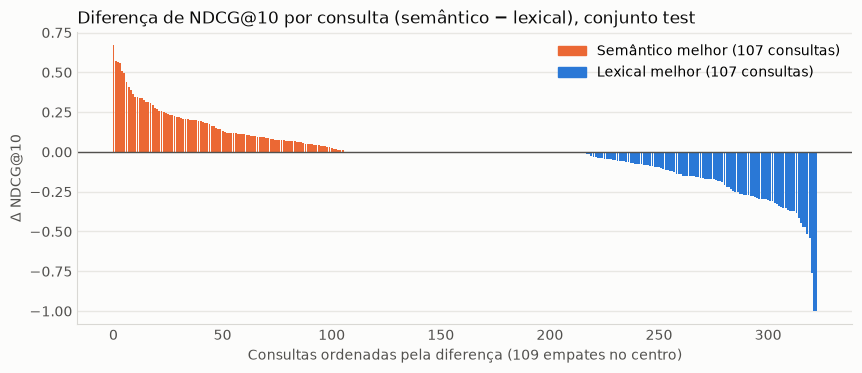

In [23]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Cores e rótulos fixos por sistema: a mesma cor identifica o mesmo sistema em todos os gráficos
CORES = {'lexical': '#2a78d6', 'semantic': '#eb6834', 'hybrid': '#1baf7a', 'reranking': '#eda100'}
ROTULOS = {'lexical': 'Lexical (BM25)', 'semantic': 'Semântico', 'hybrid': 'Híbrido (RRF)', 'reranking': 'Híbrido + reranking'}

def estilo_grafico(ax):
    """Deixa eixos e grade discretos, para que os dados fiquem em destaque."""
    ax.set_facecolor('#fcfcfb')
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)
    for lado in ['left', 'bottom']:
        ax.spines[lado].set_color('#d9d8d4')
    ax.tick_params(colors='#52514e', length=0)
    ax.grid(axis='y', color='#e8e7e3', linewidth=1)
    ax.set_axisbelow(True)

# Diferença de NDCG@10 por consulta
comp = pd.DataFrame({'query_id': ids_test,
                     'lexical': avaliacoes['lexical']['NDCG10'].values,
                     'semantico': avaliacoes['semantic']['NDCG10'].values})
comp['delta'] = comp['semantico'] - comp['lexical']
n_sem, n_lex, n_emp = (comp['delta'] > 0).sum(), (comp['delta'] < 0).sum(), (comp['delta'] == 0).sum()
print(f"Semântico melhor em {n_sem} consultas | lexical melhor em {n_lex} | empates: {n_emp} "
      f"(dos quais {((comp['lexical'] == 0) & (comp['semantico'] == 0)).sum()} com NDCG@10 = 0 nos dois)")
print(f"Diferença média: {comp['delta'].mean():+.4f} | consultas com |diferença| > 0,2: {(comp['delta'].abs() > 0.2).sum()}")
print(f"Consultas com NDCG@10 = 0: lexical {(comp['lexical'] == 0).sum()} | semântico {(comp['semantico'] == 0).sum()}")

# NDCG@10 médio por tamanho da consulta
def tipo_consulta(q):
    n = len(consultas[q].split())
    return '1 palavra' if n == 1 else ('2 ou 3 palavras' if n <= 3 else '4 ou mais palavras')

comp['tipo'] = [tipo_consulta(q) for q in comp['query_id']]
print("\nNDCG@10 médio por tamanho da consulta:")
print(comp.groupby('tipo').agg(consultas=('delta', 'size'), lexical=('lexical', 'mean'), semantico=('semantico', 'mean'),
                               diferenca=('delta', 'mean')).round(4).to_string())

ordenado = comp.sort_values('delta', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 3.8))
fig.patch.set_facecolor('#fcfcfb')
ax.bar(ordenado.index, ordenado['delta'], width=0.85,
       color=np.where(ordenado['delta'] > 0, CORES['semantic'], CORES['lexical']))
ax.axhline(0, color='#52514e', linewidth=1)
estilo_grafico(ax)
ax.set_title('Diferença de NDCG@10 por consulta (semântico − lexical), conjunto test', loc='left', color='#0b0b0b')
ax.set_xlabel(f'Consultas ordenadas pela diferença ({n_emp} empates no centro)', color='#52514e')
ax.set_ylabel('Δ NDCG@10', color='#52514e')
ax.legend(handles=[Patch(color=CORES['semantic'], label=f'Semântico melhor ({n_sem} consultas)'),
                   Patch(color=CORES['lexical'], label=f'Lexical melhor ({n_lex} consultas)')], frameon=False, loc='upper right')
fig.savefig(os.path.join(DIR_RESULTADOS, 'grafico_delta_lexical_semantico.png'), dpi=150, bbox_inches='tight')
plt.show()

### Análise por consulta: as três maiores vantagens de cada sistema

Para cada consulta mostramos o texto, os termos após o pré-processamento (com o DF e o IDF de cada um no índice), quantos documentos relevantes contêm algum termo da consulta e o Top-5 de cada método. Em cada linha do Top-5:

- `score`: BM25 no ranking lexical e cosseno no ranking semântico (as escalas são diferentes e não são comparadas entre si);
- `rel`: grau de relevância nos qrels (0 = não relevante ou não julgado);
- `tam`: tamanho do documento em tokens após o pré-processamento (a média da coleção é 165,8);
- `termos da consulta no doc (tf)`: quais termos da consulta aparecem no documento e quantas vezes;
- `pos. no outro`: posição do mesmo documento no ranking do outro sistema (`-` = fora dos 100 primeiros).

In [24]:
pos_doc = {doc_id: i for i, doc_id in enumerate(doc_ids)}                # doc_id -> posição do documento na coleção

def idf_termo(termo):
    """IDF do BM25 (mesma fórmula usada na busca)."""
    df = indice.df(termo)
    return math.log((indice.N - df + 0.5) / (df + 0.5) + 1.0)

def termos_no_doc(doc_id, termos):
    """Termos da consulta presentes no documento, no formato 'termo:tf'."""
    tokens = docs_tokens[pos_doc[doc_id]]
    return ', '.join(f'{t}:{tokens.count(t)}' for t in termos if t in tokens) or '-'

def tabela_top(ranking, q, outro_ranking, n=5):
    termos = list(dict.fromkeys(termos_da_consulta(consultas[q])))
    pos_outro = {doc_id: pos for pos, (doc_id, _) in enumerate(outro_ranking, start=1)}
    linhas = [{'pos': pos, 'doc_id': doc_id, 'score': round(score, 3), 'rel': qrels_test[q].get(doc_id, 0),
               'tam': indice.tam_docs[pos_doc[doc_id]], 'termos da consulta no doc (tf)': termos_no_doc(doc_id, termos),
               'pos. no outro': pos_outro.get(doc_id, '-'), 'título': titulos[doc_id][:75]}
              for pos, (doc_id, score) in enumerate(ranking[:n], start=1)]
    return pd.DataFrame(linhas).to_string(index=False)

def detalhar_consulta(q):
    termos = list(dict.fromkeys(termos_da_consulta(consultas[q])))
    relevantes = qrels_test[q]
    linha = comp.set_index('query_id').loc[q]
    com_termo = sum(1 for d in relevantes if d in pos_doc and any(t in docs_tokens[pos_doc[d]] for t in termos))
    print('=' * 170)
    print(f'{q}: "{consultas[q]}"')
    print(f"NDCG@10: lexical {linha['lexical']:.3f} | semântico {linha['semantico']:.3f} | diferença {linha['delta']:+.3f}")
    print("Termos da consulta: " + (', '.join(f'{t} (df={indice.df(t)}, idf={idf_termo(t):.2f})' for t in termos) or '(nenhum)'))
    print(f"Relevantes nos qrels: {len(relevantes)} (grau 2: {sum(g == 2 for g in relevantes.values())}) | "
          f"relevantes que contêm algum termo da consulta: {com_termo} | documentos devolvidos pelo BM25: {len(rank_lex_test[q])}")
    print("\nTop-5 lexical:")
    print(tabela_top(rank_lex_test[q], q, rank_sem_test[q]) if rank_lex_test[q] else '  (nenhum documento contém os termos da consulta)')
    print("\nTop-5 semântico:")
    print(tabela_top(rank_sem_test[q], q, rank_lex_test[q]))
    print()

vantagem_semantico = comp.sort_values(['delta', 'query_id'], ascending=[False, True]).head(3)['query_id'].tolist()
vantagem_lexical = comp.sort_values(['delta', 'query_id'], ascending=[True, True]).head(3)['query_id'].tolist()

print("##### TRÊS CONSULTAS COM MAIOR VANTAGEM DO SISTEMA SEMÂNTICO #####")
for q in vantagem_semantico:
    detalhar_consulta(q)

##### TRÊS CONSULTAS COM MAIOR VANTAGEM DO SISTEMA SEMÂNTICO #####
PLAIN-307: "Vitamin D: Shedding some light on the new recommendations"
NDCG@10: lexical 0.148 | semântico 0.819 | diferença +0.671
Termos da consulta: vitamin (df=222, idf=2.79), shed (df=13, idf=5.60), light (df=87, idf=3.73), new (df=313, idf=2.45), recommend (df=275, idf=2.58)
Relevantes nos qrels: 3 (grau 2: 3) | relevantes que contêm algum termo da consulta: 3 | documentos devolvidos pelo BM25: 100

Top-5 lexical:
 pos   doc_id  score  rel  tam   termos da consulta no doc (tf) pos. no outro                                                                      título
   1 MED-3099 15.825    0   62           shed:1, light:1, new:1             - The aryl hydrocarbon receptor and its xenobiotic ligands: a fundamental tri
   2 MED-4872 12.862    0  170 vitamin:14, light:1, recommend:2            16 Safety considerations and potential interactions of vitamins: should vitami
   3 MED-3373 12.481    0  147     shed:1, light

In [25]:
print("##### TRÊS CONSULTAS COM MAIOR VANTAGEM DO SISTEMA LEXICAL #####")
for q in vantagem_lexical:
    detalhar_consulta(q)

##### TRÊS CONSULTAS COM MAIOR VANTAGEM DO SISTEMA LEXICAL #####
PLAIN-1473: "kohlrabi"
NDCG@10: lexical 1.000 | semântico 0.000 | diferença -1.000
Termos da consulta: kohlrabi (df=1, idf=7.79)
Relevantes nos qrels: 1 (grau 2: 0) | relevantes que contêm algum termo da consulta: 1 | documentos devolvidos pelo BM25: 1

Top-5 lexical:
 pos   doc_id  score  rel  tam termos da consulta no doc (tf) pos. no outro                                                                      título
   1 MED-4455 11.661    1  118                     kohlrabi:2             - Glucoraphanin and 4-hydroxyglucobrassicin contents in seeds of 59 cultivars

Top-5 semântico:
 pos   doc_id  score  rel  tam termos da consulta no doc (tf) pos. no outro                                                                      título
   1 MED-3947  0.220    0  169                              -             - Hibiscus anthocyanins rich extract-induced apoptotic cell death in human pr
   2 MED-4660  0.217    0  139          

### Evidências complementares

Para sustentar a análise com valores dos próprios dados, a célula abaixo mostra:

1. a **decomposição do score BM25 por termo** (a soma das parcelas é o score do documento) para o primeiro colocado do lexical e para o relevante mais bem colocado pelo semântico, nas consultas em que o semântico venceu;
2. o tratamento de alguns termos pelo pré-processamento lexical;
3. como o tokenizador do bi-encoder divide as consultas em que o lexical venceu, o cosseno do primeiro colocado e a posição do primeiro relevante no ranking semântico completo (todos os 3.633 documentos).

In [26]:
def parcelas_bm25(q, doc_id):
    """Parcela de cada termo da consulta no score BM25 de um documento."""
    doc_idx = pos_doc[doc_id]
    norma = BM25_K1 * (1 - BM25_B + BM25_B * indice.tam_docs[doc_idx] / indice.tam_medio)
    partes = {}
    for termo, freq in Counter(termos_da_consulta(consultas[q])).items():
        tf = docs_tokens[doc_idx].count(termo)
        if tf:
            partes[termo] = round(freq * idf_termo(termo) * tf * (BM25_K1 + 1) / (tf + norma), 2)
    return partes

print("1) Decomposição do score BM25 por termo (consultas em que o semântico venceu):")
for q in vantagem_semantico:
    primeiro_lexical = rank_lex_test[q][0][0]
    relevante_semantico = next(d for d, _ in rank_sem_test[q] if qrels_test[q].get(d, 0) > 0)
    print(f'  {q} "{consultas[q]}"')
    for rotulo, d in [('1º do lexical', primeiro_lexical), ('1º relevante do semântico', relevante_semantico)]:
        print(f"     {rotulo:<26} {d} (rel={qrels_test[q].get(d, 0)}, tam={indice.tam_docs[pos_doc[d]]}): {parcelas_bm25(q, d)}")

print(f"\n2) 'd' está na lista de stopwords do NLTK: {'d' in stop_words} (por isso 'Vitamin D' vira apenas o termo 'vitamin')")
relevantes_1537 = [d for d in qrels_test['PLAIN-1537'] if d in pos_doc]
for palavra in ['carb', 'carbohydrate']:
    t = radical(palavra)
    print(f"   '{palavra}' -> radical '{t}': df = {indice.df(t)} | relevantes de PLAIN-1537 que contêm o radical: "
          f"{sum(t in docs_tokens[pos_doc[d]] for d in relevantes_1537)} de {len(relevantes_1537)}")
print(f"   'grapes' -> radical '{radical('grapes')}' (df = {indice.df(radical('grapes'))}) | "
      f"'grapefruit' -> radical '{radical('grapefruit')}' (df = {indice.df(radical('grapefruit'))})")

print("\n3) Consultas em que o lexical venceu, vistas pelo bi-encoder:")
for q in vantagem_lexical:
    similaridades = emb_docs @ modelo_bi.encode(consultas[q], normalize_embeddings=True, show_progress_bar=False)
    ordem = np.argsort(-similaridades, kind='stable')
    pos_relevante = next(p for p, i in enumerate(ordem, start=1) if qrels_test[q].get(doc_ids[i], 0) > 0)
    print(f'  {q} "{consultas[q]}": subpalavras = {modelo_bi.tokenizer.tokenize(consultas[q])} | cosseno do 1º colocado = '
          f"{similaridades[ordem[0]]:.3f} | posição do 1º relevante no ranking semântico completo: {pos_relevante}")
print(f"   'grapefruit' no tokenizador do bi-encoder: {modelo_bi.tokenizer.tokenize('grapefruit')}")
cos_primeiro = [rank_sem_test[q][0][1] for q in ids_test]
print(f"   Cosseno do 1º colocado nas {len(ids_test)} consultas do test: mediana {np.median(cos_primeiro):.3f} | "
      f"10% menores abaixo de {np.quantile(cos_primeiro, 0.1):.3f}")

1) Decomposição do score BM25 por termo (consultas em que o semântico venceu):
  PLAIN-307 "Vitamin D: Shedding some light on the new recommendations"
     1º do lexical              MED-3099 (rel=0, tam=62): {'shed': 7.52, 'light': 5.01, 'new': 3.29}
     1º relevante do semântico  MED-714 (rel=2, tam=158): {'vitamin': 5.51, 'recommend': 2.63}
  PLAIN-3085 "The Difficulty of Arriving at a Vitamin D Recommendation"
     1º do lexical              MED-3632 (rel=0, tam=153): {'arriv': 10.61}
     1º relevante do semântico  MED-4573 (rel=2, tam=135): {'vitamin': 5.75}
  PLAIN-1537 "low-carb diets"
     1º do lexical              MED-4880 (rel=0, tam=178): {'low': 3.18, 'carb': 14.8, 'diet': 2.47}
     1º relevante do semântico  MED-4515 (rel=1, tam=233): {'low': 3.06, 'diet': 2.41}

2) 'd' está na lista de stopwords do NLTK: True (por isso 'Vitamin D' vira apenas o termo 'vitamin')
   'carb' -> radical 'carb': df = 1 | relevantes de PLAIN-1537 que contêm o radical: 0 de 45
   'carbohydrat

  PLAIN-1288 "grapes": subpalavras = ['grapes'] | cosseno do 1º colocado = 0.426 | posição do 1º relevante no ranking semântico completo: 9
   'grapefruit' no tokenizador do bi-encoder: ['grape', '##fr', '##uit']
   Cosseno do 1º colocado nas 323 consultas do test: mediana 0.509 | 10% menores abaixo de 0.272


### Análise

**Visão geral.** Os dois sistemas empatam em número de vitórias: o semântico é melhor em 107 consultas, o lexical em 107, e há 109 empates (75 deles com NDCG@10 = 0 nos dois sistemas). A diferença média é pequena (−0,011, a favor do lexical), mas 81 consultas têm diferença absoluta maior que 0,2. Cada sistema acerta consultas que o outro erra.

#### Consultas com maior vantagem do sistema semântico

**1. PLAIN-307, "Vitamin D: Shedding some light on the new recommendations"** (lexical 0,148; semântico 0,819)

- *Linguagem figurada.* "Shedding some light" está em sentido figurado, mas o BM25 trata `shed` e `light` como termos comuns. `shed` é o termo mais raro da consulta (df = 13, IDF 5,60) e domina o score. O primeiro colocado, MED-3099, é um artigo sobre o receptor de hidrocarbonetos de arila cujo resumo diz "This concept sheds new light on...". Dos seus 15,83 pontos, 7,52 vêm de `shed`, 5,01 de `light` e 3,29 de `new`; ele não contém `vitamin`. O documento também é curto (62 tokens, contra a média de 165,8), e a normalização de tamanho do BM25 aumenta o peso de cada ocorrência.
- *Perda do termo "D".* A letra `d` está na lista de stopwords do NLTK. "Vitamin D" vira só `vitamin` (df = 222), e a consulta deixa de distinguir a vitamina D das outras: o 2º colocado lexical (MED-4872) trata de interações de vitaminas em geral.
- *O que o semântico faz.* Os cinco primeiros são sobre vitamina D, e dois são relevantes de grau 2: MED-714 (prevenção da deficiência de vitamina D) e MED-919 (diretriz clínica sobre avaliação, tratamento e prevenção). No lexical esses dois estavam nas posições 26 e 13: eles casam com `vitamin` e `recommend` (MED-714 soma 8,14 pontos), mas perdem para os documentos que contêm as palavras raras da expressão figurada.

**2. PLAIN-3085, "The Difficulty of Arriving at a Vitamin D Recommendation"** (lexical 0,000; semântico 0,571)

- *Termo raro fora de contexto.* `arriv` é o termo mais raro da consulta (df = 7, IDF 6,18). O primeiro colocado lexical, MED-3632, estuda a mortalidade nos Estados Unidos após a chegada ("arrival") da pluma radioativa de Fukushima. Todo o seu score (10,61) vem de `arriv`, que ocorre 4 vezes; o documento não contém `vitamin` nem `recommend`.
- *Variação de vocabulário.* Os dois únicos relevantes, MED-4573 ("Low Vitamin D Status: Definition, Prevalence, Consequences and Correction") e MED-4570 (doses de suplemento de vitamina D), contêm apenas `vitamin` entre os termos da consulta. Eles tratam do assunto da consulta (qual nível e qual dose de vitamina D são adequados) sem usar as palavras "recommendation", "difficulty" ou "arriving". O BM25 os deixa nas posições 40 e 69; o semântico, nas posições 3 e 4.

**3. PLAIN-1537, "low-carb diets"** (lexical 0,095; semântico 0,662)

- *Abreviação.* A consulta usa "carb", e os artigos escrevem "carbohydrate". Para o índice lexical são termos diferentes: `carb` tem df = 1 e `carbohydr` tem df = 143. Nenhum dos 45 relevantes contém `carb`.
- O único documento com `carb` (MED-4880, tf = 8) recebe desse termo 14,80 dos seus 20,44 pontos e fica em 1º, sem ser relevante. Depois dele, o ranking depende só de `low` e `diet`, termos muito frequentes (df = 726 e 1.041) e pouco discriminativos: aparecem dietas "low-calorie" e "low-protein" (MED-2943 e MED-1714).
- O bi-encoder aproxima "low-carb" de "low-carbohydrate": 4 dos 5 primeiros são relevantes, e três deles trazem "low-carbohydrate" no título. Um deles (MED-2586) nem aparece entre os 100 primeiros do lexical.

#### Consultas com maior vantagem do sistema lexical

**4. PLAIN-1473, "kohlrabi"** (lexical 1,000; semântico 0,000)

- *Termo raro com correspondência exata.* `kohlrabi` (couve-rábano) ocorre em um único documento da coleção (df = 1), que é o único relevante: MED-4455, cujo título lista as hortaliças analisadas, entre elas "kohlrabi". O BM25 devolve exatamente esse documento.
- O bi-encoder não tem uma representação útil para a palavra: o tokenizador a quebra em `ko ##hl ##ra ##bi`, fragmentos sem significado. O cosseno do primeiro colocado é 0,220, abaixo do limite dos 10% menores valores do `test` (0,272; a mediana é 0,509), e os cinco primeiros tratam de hibisco e de algas. O documento relevante fica na posição 117 do ranking semântico completo.

**5. PLAIN-2081, "shelf life"** (lexical 1,000; semântico 0,000)

- *Expressão composta e ambiguidade.* "Shelf life" (prazo de validade) tem um sentido que não é a soma das duas palavras. O bi-encoder puxa a consulta para o sentido geral de "life": entre os cinco primeiros estão MED-1378 ("Longevity and diet"), MED-2510 (extensão da vida por restrição alimentar) e MED-1433 (envelhecimento). Nenhum dos cinco contém `shelf`.
- No BM25, `shelf` é raro (df = 7, IDF 6,18) e ancora o ranking. O único relevante, MED-4303 ("Oxidative stability and shelf-life evaluation of selected culinary oils"), contém `shelf` e `life` 4 vezes cada e fica em 1º (score 14,68, contra 11,79 do segundo). No semântico ele está na posição 15.

**6. PLAIN-1288, "grapes"** (lexical 0,890; semântico 0,130)

- *Confusão entre palavras de grafia parecida.* Quatro dos cinco primeiros do semântico são sobre **grapefruit** (toranja), outra fruta: MED-3200, MED-398, MED-3207 e MED-3210. Nenhum deles contém o termo `grape`. O tokenizador do bi-encoder divide "grapefruit" em `grape ##fr ##uit`, que começa pelo mesmo fragmento da consulta, o que provavelmente aproxima os embeddings. No índice lexical, `grape` (df = 29) e `grapefruit` (df = 22) são termos distintos.
- O BM25 devolve só os 29 documentos que contêm `grape`, e 4 dos 5 primeiros são relevantes.
- *Ressalva.* A consulta tem 196 relevantes, e apenas 15 contêm `grape`. O lexical vence no Top-10, mas não alcança os outros 181; a vantagem aqui é de precisão no topo, e não de cobertura.

#### Síntese

- **O semântico vence** quando a consulta e os documentos relevantes usam palavras diferentes para o mesmo assunto (abreviação "carb" e "carbohydrate"; "recommendation" e textos sobre níveis e doses) e quando a consulta traz palavras raras que não carregam o tema ("shedding light", "arriving at"). Nesses casos o IDF alto, que normalmente ajuda o BM25, passa a atrapalhar.
- **O lexical vence** quando a consulta é um termo específico que ocorre literalmente em poucos documentos (`kohlrabi`, `shelf`, `grape`). O bi-encoder falhou de três formas: palavra rara sem representação própria, expressão composta interpretada pelo sentido mais comum e confusão com uma palavra parecida.
- **Sobre os qrels.** Os julgamentos do NFCorpus foram extraídos automaticamente das ligações entre as páginas do site NutritionFacts.org e os artigos citados (Boteva et al., 2016), e não de um julgamento exaustivo. Por isso `rel = 0` inclui documentos nunca julgados, como os artigos sobre vitamina D que aparecem com `rel = 0` no Top-5 semântico da PLAIN-307.

## Requisito 8: Busca híbrida (Reciprocal Rank Fusion)

O RRF combina os dois rankings usando apenas as **posições** dos documentos, e não os scores. Isso evita comparar diretamente o BM25 (sem limite superior) com o cosseno (entre −1 e 1). O score de um documento $d$ é

$$RRF(d) = \sum_{s} \frac{1}{k + rank_s(d)}$$

em que $rank_s(d)$ é a posição de $d$ (começando em 1) no ranking do sistema $s$. São fundidos os 100 primeiros documentos de cada sistema; um documento ausente de um dos rankings não recebe a parcela daquele sistema. O parâmetro $k$ controla o peso das primeiras posições: com $k$ pequeno, estar no topo de um único sistema vale muito; com $k$ grande, as parcelas ficam parecidas e ganha quem aparece nos dois rankings.

In [27]:
def fusao_rrf(rankings, k, top_n=TOP_N):
    """Funde os top_n primeiros documentos de cada ranking. Devolve [(doc_id, score RRF), ...] em ordem decrescente."""
    scores = {}
    for ranking in rankings:
        for pos, (doc_id, _) in enumerate(ranking[:top_n], start=1):
            scores[doc_id] = scores.get(doc_id, 0.0) + 1.0 / (k + pos)
    return sorted(scores.items(), key=lambda par: (-par[1], par[0]))     # empates: doc_id crescente

# Exemplo com rankings pequenos e k = 60: 'b' está em 2º e 1º; 'a' em 1º e 3º; 'c' só no primeiro ranking
print(fusao_rrf([[('a', 9.1), ('b', 7.5), ('c', 3.0)], [('b', 0.8), ('d', 0.7), ('a', 0.6)]], k=60))
print("b:", 1 / (60 + 2) + 1 / (60 + 1), "| a:", 1 / (60 + 1) + 1 / (60 + 3), "| c:", 1 / (60 + 3))

[('b', 0.03252247488101534), ('a', 0.032266458495966696), ('d', 0.016129032258064516), ('c', 0.015873015873015872)]
b: 0.03252247488101534 | a: 0.032266458495966696 | c: 0.015873015873015872


### Ajuste de $k$ no conjunto `dev`

In [28]:
linhas = []
for k in VALORES_K_RRF:
    rankings = {q: fusao_rrf([rank_lex_dev[q], rank_sem_dev[q]], k) for q in ids_dev}
    linhas.append({'k': k, **avaliar(rankings, qrels_dev, ids_dev)[METRICAS].mean()})
df_rrf_dev = pd.DataFrame(linhas).set_index('k')
K_RRF = int(df_rrf_dev['NDCG10'].idxmax())                               # escolhido no dev

referencia_dev = pd.DataFrame({'lexical (dev)': avaliar(rank_lex_dev, qrels_dev, ids_dev)[METRICAS].mean(),
                               'semântico (dev)': avaliar(rank_sem_dev, qrels_dev, ids_dev)[METRICAS].mean()}).T
print(df_rrf_dev.round(4).to_string())
print(f"\nValor escolhido no dev: k = {K_RRF}")
print("\nReferência no dev (sistemas isolados):")
print(referencia_dev.round(4).to_string())

        P10     R10    AP10  NDCG10
k                                  
10   0.2623  0.1482  0.1064  0.3307
60   0.2611  0.1508  0.1065  0.3291
100  0.2630  0.1510  0.1066  0.3304

Valor escolhido no dev: k = 10

Referência no dev (sistemas isolados):
                    P10     R10    AP10  NDCG10
lexical (dev)    0.2361  0.1289  0.0922  0.2959
semântico (dev)  0.2401  0.1364  0.0947  0.3024


### Avaliação no conjunto `test`

O valor de $k$ escolhido no `dev` é mantido. O ranking híbrido de cada consulta tem entre 100 e 200 documentos (a união dos dois Top-100); os 100 primeiros são gravados em `results_hybrid.csv`.

In [29]:
rank_hib_dev = {q: fusao_rrf([rank_lex_dev[q], rank_sem_dev[q]], K_RRF) for q in ids_dev}

rank_hib_test, tempos_fusao = {}, []
for q in ids_test:
    t0 = time.perf_counter()
    rank_hib_test[q] = fusao_rrf([rank_lex_test[q], rank_sem_test[q]], K_RRF)
    tempos_fusao.append(time.perf_counter() - t0)
tempo_medio['fusao'] = float(np.mean(tempos_fusao))

avaliacoes['hybrid'] = avaliar(rank_hib_test, qrels_test, ids_test)
salvar_ranking(rank_hib_test, 'results_hybrid.csv')

print(tabela_medias(['lexical', 'semantic', 'hybrid']).round(4).to_string())
print(f"\nhybrid: maior diferença em relação ao ir_measures: {conferir_com_ir_measures('hybrid', rank_hib_test):.2e}")
print(f"Tempo médio da fusão: {1000 * tempo_medio['fusao']:.3f} ms por consulta")

# Evidências para a análise: sobreposição dos rankings e comportamento por consulta
em_comum_10 = [len({d for d, _ in rank_lex_test[q][:10]} & {d for d, _ in rank_sem_test[q][:10]}) for q in ids_test]
em_comum_100 = [len({d for d, _ in rank_lex_test[q]} & {d for d, _ in rank_sem_test[q]}) for q in ids_test]
print(f"\nDocumentos em comum entre lexical e semântico: {np.mean(em_comum_10):.1f} no Top-10 | {np.mean(em_comum_100):.1f} no Top-100 (médias)")

lex, sem, hib = (avaliacoes[s]['NDCG10'].values for s in ['lexical', 'semantic', 'hybrid'])
melhor, pior = np.maximum(lex, sem), np.minimum(lex, sem)
print(f"Híbrido acima dos dois sistemas: {(hib > melhor).sum()} consultas | igual ao melhor: {(hib == melhor).sum()} | "
      f"entre os dois: {((hib < melhor) & (hib > pior)).sum()} | igual ao pior (com sistemas diferentes): {((hib == pior) & (pior < melhor)).sum()} | abaixo dos dois: {(hib < pior).sum()}")
vazias = [q for q in ids_test if not rank_lex_test[q]]
idx_vazias = [ids_test.index(q) for q in vazias]
print(f"Nas {len(vazias)} consultas sem resultado lexical: NDCG@10 médio do semântico {sem[idx_vazias].mean():.4f} | híbrido {hib[idx_vazias].mean():.4f}")

# As seis consultas analisadas no Requisito 7: o que a fusão fez em cada uma
seis = comp.set_index('query_id').loc[vantagem_semantico + vantagem_lexical, ['lexical', 'semantico']]
seis['hibrido'] = avaliacoes['hybrid'].set_index('query_id').loc[seis.index, 'NDCG10']
seis.insert(0, 'consulta', [consultas[q][:40] for q in seis.index])
print("\nNDCG@10 nas seis consultas do Requisito 7:")
print(seis.round(3).to_string())

# Cálculo do RRF aberto para os três primeiros do híbrido em uma consulta de exemplo
q = 'PLAIN-2430'
pos_lex = {d: p for p, (d, _) in enumerate(rank_lex_test[q], start=1)}
pos_sem = {d: p for p, (d, _) in enumerate(rank_sem_test[q], start=1)}
print(f'\nExemplo ({q}: "{consultas[q]}"), três primeiros do híbrido:')
for doc_id, score in rank_hib_test[q][:3]:
    parcelas = [f"1/({K_RRF}+{p[doc_id]})" for p in (pos_lex, pos_sem) if doc_id in p]
    print(f"  {doc_id}: posição lexical {pos_lex.get(doc_id, '-')}, posição semântica {pos_sem.get(doc_id, '-')} -> {' + '.join(parcelas)} = {score:.5f}")

            P@10    R@10  MAP@10  NDCG@10
lexical   0.2393  0.1533  0.1218   0.3280
semantic  0.2433  0.1550  0.1108   0.3167
hybrid    0.2604  0.1754  0.1353   0.3549

hybrid: maior diferença em relação ao ir_measures: 2.22e-16
Tempo médio da fusão: 0.059 ms por consulta

Documentos em comum entre lexical e semântico: 2.9 no Top-10 | 22.8 no Top-100 (médias)
Híbrido acima dos dois sistemas: 51 consultas | igual ao melhor: 136 | entre os dois: 117 | igual ao pior (com sistemas diferentes): 13 | abaixo dos dois: 6
Nas 15 consultas sem resultado lexical: NDCG@10 médio do semântico 0.0258 | híbrido 0.0258

NDCG@10 nas seis consultas do Requisito 7:
                                            consulta  lexical  semantico  hibrido
query_id                                                                         
PLAIN-307   Vitamin D: Shedding some light on the ne    0.148      0.819    0.733
PLAIN-3085  The Difficulty of Arriving at a Vitamin     0.000      0.571    0.403
PLAIN-1537        

**Análise.**

- **Ajuste de $k$.** No `dev`, os três valores ficam muito próximos (NDCG@10 de 0,3307, 0,3291 e 0,3304 para $k$ = 10, 60 e 100; diferença máxima de 0,0016). O RRF é pouco sensível a $k$ nesta coleção. Pelo critério definido, usamos $k = 10$.
- **Resultado no `test`.** O híbrido supera os dois sistemas nas quatro métricas. O NDCG@10 é de 0,3549, contra 0,3280 do lexical (+8,2%) e 0,3167 do semântico (+12,1%). O R@10 sobe para 0,1754 (contra 0,1533 e 0,1550) e o MAP@10 para 0,1353 (contra 0,1218 e 0,1108). O ganho já aparecia no `dev` (0,3307, contra 0,2959 e 0,3024).
- **Por que funciona.** Os rankings são complementares: em média, lexical e semântico têm só 2,9 documentos em comum no Top-10 (22,8 no Top-100). Um documento presente nos dois rankings soma duas parcelas e sobe; um documento bem colocado em apenas um deles ainda entra no ranking fundido.
- **Por consulta.** O híbrido fica acima dos dois sistemas em 51 consultas e iguala o melhor em 136. Em 117 fica entre os dois, e em apenas 6 fica abaixo de ambos. A fusão raramente é pior que os dois sistemas, mas também não escolhe o melhor de cada consulta. As seis consultas do Requisito 7 mostram os dois lados:
  - quando um sistema falha por completo, o híbrido preserva boa parte do resultado do outro (0,733 em PLAIN-307; 1,000 em "shelf life");
  - o sistema que falhou também injeta documentos irrelevantes no topo. Em "low-carb diets" o híbrido fica em 0,385, contra 0,662 do semântico. Em "kohlrabi", o único documento do lexical empata em score com o primeiro do semântico (ambos valem 1/11) e fica em 2º pelo critério de desempate (NDCG@10 de 0,631).
- **Limite.** Nas 15 consultas sem resultado lexical, o híbrido é idêntico ao semântico (NDCG@10 médio de 0,0258 nos dois). A fusão não cria informação que nenhum dos dois sistemas possui.
- **Custo.** A fusão leva centésimos de milissegundo por consulta, desprezível diante das duas buscas.

## Requisito 9: Reranking com cross-encoder

O ranking híbrido é o recuperador inicial. Os **50 primeiros** documentos de cada consulta são reordenados por um **cross-encoder**: diferente do bi-encoder, ele recebe a consulta e o documento **juntos** na mesma entrada e produz um único score de relevância. Como a atenção do modelo relaciona diretamente as palavras da consulta com as do documento, o score tende a ser mais preciso. O custo é que nada pode ser pré-calculado: cada par (consulta, documento) exige uma passagem pelo modelo, e por isso ele é aplicado só a poucos candidatos.

Os documentos abaixo da posição 50 permanecem na mesma ordem relativa do híbrido, de modo que o ranking continua completo.

**Candidatos:** dois cross-encoders pré-treinados no MS MARCO (ranking de passagens), da biblioteca Sentence Transformers: `ms-marco-MiniLM-L6-v2` (6 camadas, o exemplo do enunciado) e `ms-marco-TinyBERT-L2-v2` (2 camadas, bem mais rápido). Como o reranking é a etapa mais lenta do pipeline, a comparação verifica se o modelo menor seria suficiente. A escolha é feita pelo NDCG@10 no `dev`. Os dois aceitam no máximo 512 tokens por par (consulta + documento); pares mais longos são truncados.

Os scores do cross-encoder são gravados em `artefatos/` junto com o tempo medido, para não repetir o cálculo a cada execução.

In [30]:
CROSS_ENCODERS = {                                       # nome do modelo -> revisão fixada
    'cross-encoder/ms-marco-TinyBERT-L2-v2': '81d1926f67cb8eee2c2be17ca9f793c7c3bd20cc',
    'cross-encoder/ms-marco-MiniLM-L6-v2': '233902d25c440f23af6f7d6e94d2946bac0bee0a',
}

def scores_cross_encoder(nome, split, ids_consultas, rankings_hibridos):
    """Score do cross-encoder para os TOP_RERANK primeiros documentos do híbrido de cada consulta.
    Devolve um dicionário com os scores ({query_id: {doc_id: score}}), o tempo médio por consulta e o truncamento."""
    caminho = os.path.join(DIR_ARTEFATOS, f"cross_{nome.split('/')[-1]}_{split}.json")
    candidatos = {q: [doc_id for doc_id, _ in rankings_hibridos[q][:TOP_RERANK]] for q in ids_consultas}

    if os.path.exists(caminho):
        with open(caminho) as f:
            salvo = json.load(f)
        # só reaproveita se os scores salvos cobrem exatamente os candidatos atuais
        if all(set(candidatos[q]) == set(salvo['scores'].get(q, {})) for q in ids_consultas):
            return salvo

    modelo = CrossEncoder(nome, revision=CROSS_ENCODERS[nome], device=DEVICE)
    scores, tempos, n_pares, n_truncados = {}, [], 0, 0
    for q in ids_consultas:
        pares = [(consultas[q], corpus[doc_id]) for doc_id in candidatos[q]]
        t0 = time.perf_counter()
        saida = modelo.predict(pares, batch_size=16, show_progress_bar=False)
        tempos.append(time.perf_counter() - t0)
        scores[q] = {doc_id: float(s) for doc_id, s in zip(candidatos[q], saida)}
        # truncamento: nº de tokens do par sem truncar (fora da medição de tempo)
        tokens = modelo.tokenizer([consultas[q]] * len(pares), [corpus[d] for d in candidatos[q]], truncation=False)['input_ids']
        n_pares += len(pares)
        n_truncados += sum(len(ids) > modelo.max_seq_length for ids in tokens)

    salvo = {'modelo': nome, 'revisao': CROSS_ENCODERS[nome], 'max_tokens': int(modelo.max_seq_length), 'pares': n_pares,
             'pares_truncados': n_truncados, 'tempo_medio_consulta_s': float(np.mean(tempos)), 'dispositivo': DEVICE,
             'scores': scores}
    with open(caminho, 'w') as f:
        json.dump(salvo, f)
    return salvo

# Abaixo do Top-50 a ordem é a do híbrido. Para que o arquivo de resultados continue ordenado pela coluna score,
# esses documentos recebem o score do RRF menos uma constante, que os deixa abaixo de qualquer score do cross-encoder.
DESLOCAMENTO_CAUDA = 100.0

def reordenar(ranking_hibrido, scores_ce):
    """Reordena os TOP_RERANK primeiros pelo score do cross-encoder; os demais mantêm a ordem do híbrido."""
    topo = sorted(((doc_id, scores_ce[doc_id]) for doc_id, _ in ranking_hibrido[:TOP_RERANK]), key=lambda par: (-par[1], par[0]))
    assert topo[-1][1] > 1 - DESLOCAMENTO_CAUDA
    cauda = [(doc_id, score_rrf - DESLOCAMENTO_CAUDA) for doc_id, score_rrf in ranking_hibrido[TOP_RERANK:]]
    return topo + cauda

### Escolha do modelo de reranking no conjunto `dev`

In [31]:
ndcg_hib_dev = avaliar(rank_hib_dev, qrels_dev, ids_dev)['NDCG10'].mean()
linhas = [{'modelo': 'híbrido sem reranking', 'NDCG10': ndcg_hib_dev}]
for nome in CROSS_ENCODERS:
    salvo = scores_cross_encoder(nome, 'dev', ids_dev, rank_hib_dev)
    rankings = {q: reordenar(rank_hib_dev[q], salvo['scores'][q]) for q in ids_dev}
    medias = avaliar(rankings, qrels_dev, ids_dev)[METRICAS].mean()
    linhas.append({'modelo': nome.split('/')[-1], **medias, 'tempo_por_consulta_s': salvo['tempo_medio_consulta_s'],
                   'pares_truncados_%': 100 * salvo['pares_truncados'] / salvo['pares']})
df_ce_dev = pd.DataFrame(linhas).set_index('modelo')
print(df_ce_dev.round(4).to_string(na_rep='-'))

MODELO_CROSS = max(CROSS_ENCODERS, key=lambda nome: df_ce_dev.loc[nome.split('/')[-1], 'NDCG10'])     # escolhido no dev
print(f"\nModelo de reranking escolhido no dev: {MODELO_CROSS}")

                         NDCG10    P10     R10    AP10  tempo_por_consulta_s  pares_truncados_%
modelo                                                                                         
híbrido sem reranking    0.3307      -       -       -                     -                  -
ms-marco-TinyBERT-L2-v2  0.3252  0.258  0.1494  0.1073                0.3458              8.179
ms-marco-MiniLM-L6-v2    0.3317  0.262  0.1548  0.1086                4.8638              8.179

Modelo de reranking escolhido no dev: cross-encoder/ms-marco-MiniLM-L6-v2


**Análise.** O `ms-marco-MiniLM-L6-v2` tem o maior NDCG@10 no `dev` (0,3317) e é o modelo adotado. O ganho sobre o híbrido sem reranking (0,3307) é de apenas 0,001. O `ms-marco-TinyBERT-L2-v2` foi cerca de 14 vezes mais rápido na nossa execução (0,35 s contra 4,86 s por consulta em CPU), mas **piora** o ranking híbrido (0,3252): o modelo de 2 camadas não é preciso o bastante para reordenar candidatos que já passaram por dois sistemas. Cerca de 8% dos pares (consulta, documento) passam de 512 tokens e são truncados.

### Avaliação final no conjunto `test`: Lexical, Semântico, Híbrido e Híbrido + reranking

In [32]:
info_ce = scores_cross_encoder(MODELO_CROSS, 'test', ids_test, rank_hib_test)
rank_rer_test = {q: reordenar(rank_hib_test[q], info_ce['scores'][q]) for q in ids_test}
tempo_medio['reranking'] = info_ce['tempo_medio_consulta_s']

avaliacoes['reranking'] = avaliar(rank_rer_test, qrels_test, ids_test)
salvar_ranking(rank_rer_test, 'results_reranking.csv')

SISTEMAS = ['lexical', 'semantic', 'hybrid', 'reranking']
tabela_final = tabela_medias(SISTEMAS)
print(tabela_final.round(4).to_string())
print(f"\nreranking: maior diferença em relação ao ir_measures: {conferir_com_ir_measures('reranking', rank_rer_test):.2e}")

# metrics_per_query.csv: uma linha por (consulta, sistema); a média de AP10 de cada sistema é o MAP@10 da tabela
df_metricas = pd.concat([avaliacoes[s].assign(model=s) for s in SISTEMAS])[['query_id', 'model'] + METRICAS]
df_metricas.to_csv(os.path.join(DIR_RESULTADOS, 'metrics_per_query.csv'), index=False)

print(f"\nCross-encoder: {info_ce['modelo']} (revisão {info_ce['revisao'][:10]}) | entrada máxima: {info_ce['max_tokens']} tokens")
print(f"Pares (consulta, documento) avaliados no test: {info_ce['pares']} | truncados: {info_ce['pares_truncados']} "
      f"({100 * info_ce['pares_truncados'] / info_ce['pares']:.1f}%)")

# Tempo médio por consulta de cada etapa
tempos = pd.Series({'busca lexical (BM25)': tempo_medio['lexical'], 'busca semântica (bi-encoder)': tempo_medio['semantico'],
                    'fusão (RRF)': tempo_medio['fusao'], f'reranking ({TOP_RERANK} pares, cross-encoder)': tempo_medio['reranking']})
tempos['pipeline completo'] = tempos.sum()
print(f"\nTempo médio por consulta ({info_ce['dispositivo']}), em milissegundos:")
print((1000 * tempos).round(2).to_string())

             P@10    R@10  MAP@10  NDCG@10
lexical    0.2393  0.1533  0.1218   0.3280
semantic   0.2433  0.1550  0.1108   0.3167
hybrid     0.2604  0.1754  0.1353   0.3549
reranking  0.2511  0.1674  0.1389   0.3564



reranking: maior diferença em relação ao ir_measures: 2.22e-16

Cross-encoder: cross-encoder/ms-marco-MiniLM-L6-v2 (revisão 233902d25c) | entrada máxima: 512 tokens
Pares (consulta, documento) avaliados no test: 16150 | truncados: 1424 (8.8%)

Tempo médio por consulta (cpu), em milissegundos:
busca lexical (BM25)                      0.26
busca semântica (bi-encoder)            159.63
fusão (RRF)                               0.06
reranking (50 pares, cross-encoder)    4718.60
pipeline completo                      4878.55


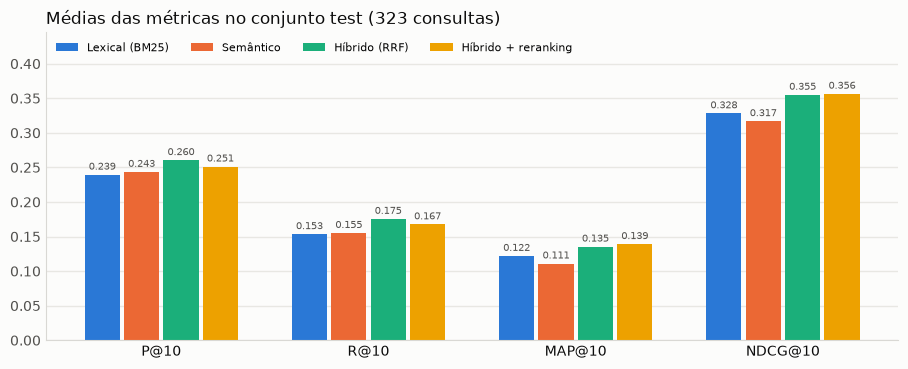

In [33]:
# Gráfico: os quatro sistemas nas quatro métricas (os valores exatos estão na tabela acima)
fig, ax = plt.subplots(figsize=(11, 4))
fig.patch.set_facecolor('#fcfcfb')
largura = 0.19
for i, s in enumerate(SISTEMAS):
    x = np.arange(len(tabela_final.columns)) + (i - 1.5) * largura
    barras = ax.bar(x, tabela_final.loc[s], width=largura - 0.02, color=CORES[s], label=ROTULOS[s])
    ax.bar_label(barras, labels=[f'{v:.3f}' for v in tabela_final.loc[s]], fontsize=7, color='#52514e', padding=2)
estilo_grafico(ax)
ax.set_xticks(np.arange(len(tabela_final.columns)))
ax.set_xticklabels(tabela_final.columns, color='#0b0b0b')
ax.set_ylim(0, tabela_final.values.max() * 1.25)
ax.set_title('Médias das métricas no conjunto test (323 consultas)', loc='left', color='#0b0b0b')
ax.legend(frameon=False, ncol=4, loc='upper left', fontsize=8)
fig.savefig(os.path.join(DIR_RESULTADOS, 'grafico_comparacao_sistemas.png'), dpi=150, bbox_inches='tight')
plt.show()

**Análise.**

- **Comparação geral.** O híbrido e o híbrido + reranking são os melhores sistemas: o NDCG@10 do reranking (0,3564) está 8,7% acima do lexical (0,3280) e 12,5% acima do semântico (0,3167). Quase todo esse ganho vem da fusão: o reranking acrescenta só 0,0015 ao NDCG@10 do híbrido (0,3549).
- **O reranking melhora o topo e piora o conjunto do Top-10.** O MAP@10 sobe (0,1353 → 0,1389), mas P@10 e R@10 caem (0,2604 → 0,2511 e 0,1754 → 0,1674). O Requisito 10 mostra o motivo: o cross-encoder acerta mais vezes o primeiro documento, mas troca relevantes por não relevantes nas posições seguintes. NDCG e AP dão mais peso às primeiras posições e por isso sobem um pouco; as métricas que só contam relevantes no Top-10 descem.
- **Custo.** O reranking responde por cerca de 97% do tempo do pipeline: aproximadamente 4,7 s por consulta em CPU, contra cerca de 0,15 s da busca semântica e menos de 1 ms da busca lexical e da fusão. Neste hardware e nesta coleção, é a etapa mais cara e a de menor retorno em qualidade de ranking. Com GPU o tempo cairia bastante, mas o ganho de qualidade seria o mesmo.
- **Truncamento.** 8,8% dos pares do `test` (1.424 de 16.150) passam de 512 tokens e têm o final do documento cortado.

## Requisito 10: Análise do reranking

Comparamos, consulta a consulta, o NDCG@10 do híbrido antes e depois do reranking, e selecionamos:

- os **dois casos de maior ganho**;
- um caso de **pouca ou nenhuma alteração**: entre as consultas com a menor diferença absoluta, a de maior NDCG@10 no híbrido (ou seja, havia um bom ranking a preservar);
- o caso de **maior piora**.

Para cada caso mostramos os documentos que estão no Top-10 antes ou depois do reranking, com a posição nos dois rankings, o grau de relevância e o score do cross-encoder.

In [34]:
comp_rer = pd.DataFrame({'query_id': ids_test,
                         'hibrido': avaliacoes['hybrid']['NDCG10'].values,
                         'reranking': avaliacoes['reranking']['NDCG10'].values})
comp_rer['delta'] = comp_rer['reranking'] - comp_rer['hibrido']
print(f"Reranking melhorou {(comp_rer['delta'] > 0).sum()} consultas | piorou {(comp_rer['delta'] < 0).sum()} | "
      f"não alterou o NDCG@10 de {(comp_rer['delta'] == 0).sum()} | diferença média: {comp_rer['delta'].mean():+.4f}")

# Onde o reranking muda o ranking: relevantes no topo, antes e depois
def media_relevantes(rankings, n):
    return np.mean([sum(qrels_test[q].get(d, 0) > 0 for d, _ in rankings[q][:n]) for q in ids_test])
print(pd.DataFrame({nome: {'consultas com relevante na 1ª posição': sum(qrels_test[q].get(r[q][0][0], 0) > 0 for q in ids_test),
                           'relevantes no Top-3 (média)': media_relevantes(r, 3),
                           'relevantes no Top-10 (média)': media_relevantes(r, 10)}
                    for nome, r in [('híbrido', rank_hib_test), ('reranking', rank_rer_test)]}).round(3).to_string())

# Efeito do reranking por tamanho da consulta e nas consultas em forma de pergunta
comp_rer['tipo'] = [tipo_consulta(q) for q in comp_rer['query_id']]
print("\nDiferença de NDCG@10 (reranking − híbrido) por tamanho da consulta:")
print(comp_rer.groupby('tipo').agg(consultas=('delta', 'size'), hibrido=('hibrido', 'mean'), reranking=('reranking', 'mean'),
                                   diferenca=('delta', 'mean'), melhorou=('delta', lambda d: (d > 0).sum()),
                                   piorou=('delta', lambda d: (d < 0).sum())).round(4).to_string())
eh_pergunta = np.array([consultas[q].strip().endswith('?') for q in comp_rer['query_id']])
print(f"Consultas em forma de pergunta ({eh_pergunta.sum()}): diferença média {comp_rer.loc[eh_pergunta, 'delta'].mean():+.4f} | "
      f"demais ({(~eh_pergunta).sum()}): {comp_rer.loc[~eh_pergunta, 'delta'].mean():+.4f}")

# Teto do reranking: ele só pode promover relevantes que já estão entre os 50 candidatos
rel_top50 = [sum(qrels_test[q].get(d, 0) > 0 for d, _ in rank_hib_test[q][:TOP_RERANK]) for q in ids_test]
print(f"Relevantes entre os {TOP_RERANK} candidatos: {np.mean(rel_top50):.1f} por consulta, em média | "
      f"consultas sem nenhum relevante entre os candidatos: {sum(n == 0 for n in rel_top50)}")

casos_ganho = comp_rer.sort_values(['delta', 'query_id'], ascending=[False, True]).head(2)['query_id'].tolist()
caso_piora = comp_rer.sort_values(['delta', 'query_id'], ascending=[True, True]).iloc[0]['query_id']
menor_dif = comp_rer['delta'].abs().min()
caso_estavel = (comp_rer[comp_rer['delta'].abs() == menor_dif]
                .sort_values(['hibrido', 'query_id'], ascending=[False, True]).iloc[0]['query_id'])

# Tokenizador do cross-encoder escolhido, para mostrar o tamanho de cada par (consulta, documento) e as subpalavras
tok_ce = transformers.AutoTokenizer.from_pretrained(MODELO_CROSS, revision=CROSS_ENCODERS[MODELO_CROSS])

def mostrar_mudancas(q):
    """Documentos que estão no Top-10 do híbrido ou do reranking, com a posição em cada ranking."""
    pos_hib = {d: p for p, (d, _) in enumerate(rank_hib_test[q], start=1)}
    pos_rer = {d: p for p, (d, _) in enumerate(rank_rer_test[q], start=1)}
    pos_lex = {d: p for p, (d, _) in enumerate(rank_lex_test[q], start=1)}
    pos_sem = {d: p for p, (d, _) in enumerate(rank_sem_test[q], start=1)}
    termos = list(dict.fromkeys(termos_da_consulta(consultas[q])))
    docs = sorted({d for d, _ in rank_hib_test[q][:10]} | {d for d, _ in rank_rer_test[q][:10]}, key=lambda d: pos_rer[d])
    linhas = [{'pos. reranking': pos_rer[d], 'pos. híbrido': pos_hib[d], 'mudança': pos_hib[d] - pos_rer[d],
               'rel': qrels_test[q].get(d, 0), 'score cross-enc.': round(info_ce['scores'][q][d], 2),
               'pos. lexical': pos_lex.get(d, '-'), 'pos. semântico': pos_sem.get(d, '-'),
               'tokens do par': len(tok_ce(consultas[q], corpus[d], truncation=False)['input_ids']),
               'termos da consulta no doc (tf)': termos_no_doc(d, termos), 'doc_id': d, 'título': titulos[d][:50]} for d in docs]
    linha = comp_rer.set_index('query_id').loc[q]
    rel10_antes = sum(qrels_test[q].get(d, 0) > 0 for d, _ in rank_hib_test[q][:10])
    rel10_depois = sum(qrels_test[q].get(d, 0) > 0 for d, _ in rank_rer_test[q][:10])
    print('=' * 170)
    print(f'{q}: "{consultas[q]}"')
    print(f"NDCG@10: híbrido {linha['hibrido']:.3f} -> reranking {linha['reranking']:.3f} (diferença {linha['delta']:+.3f}) | "
          f"relevantes no Top-10: {rel10_antes} -> {rel10_depois} | relevantes entre os {TOP_RERANK} candidatos: "
          f"{sum(qrels_test[q].get(d, 0) > 0 for d, _ in rank_hib_test[q][:TOP_RERANK])} | relevantes nos qrels: {len(qrels_test[q])}")
    print(f"(mudança > 0: o documento subiu com o reranking; mudança < 0: desceu | tokens do par > {info_ce['max_tokens']}: documento truncado)")
    print(pd.DataFrame(linhas).to_string(index=False))
    print("Títulos completos dos três primeiros após o reranking e dos relevantes da tabela:")
    for d in docs:
        if pos_rer[d] <= 3 or qrels_test[q].get(d, 0) > 0:
            print(f"  {d} (pos. {pos_rer[d]}, rel={qrels_test[q].get(d, 0)}): {titulos[d]}")
    print()

print("\n##### DOIS CASOS DE MAIOR GANHO #####")
for q in casos_ganho:
    mostrar_mudancas(q)

Reranking melhorou 104 consultas | piorou 97 | não alterou o NDCG@10 de 122 | diferença média: +0.0015
                                       híbrido  reranking
consultas com relevante na 1ª posição  155.000    165.000
relevantes no Top-3 (média)              1.176      1.186
relevantes no Top-10 (média)             2.604      2.511

Diferença de NDCG@10 (reranking − híbrido) por tamanho da consulta:
                    consultas  hibrido  reranking  diferenca  melhorou  piorou
tipo                                                                          
1 palavra                 103   0.4006     0.3922    -0.0084        22      27
2 ou 3 palavras            89   0.3397     0.3429     0.0033        29      27
4 ou mais palavras        131   0.3292     0.3373     0.0080        53      43
Consultas em forma de pergunta (42): diferença média +0.0094 | demais (281): +0.0003
Relevantes entre os 50 candidatos: 6.1 por consulta, em média | consultas sem nenhum relevante entre os candidatos: 


##### DOIS CASOS DE MAIOR GANHO #####
PLAIN-1320: "Harvard Physicians’ Study II"
NDCG@10: híbrido 0.000 -> reranking 0.562 (diferença +0.562) | relevantes no Top-10: 0 -> 3 | relevantes entre os 50 candidatos: 3 | relevantes nos qrels: 6
(mudança > 0: o documento subiu com o reranking; mudança < 0: desceu | tokens do par > 512: documento truncado)
 pos. reranking  pos. híbrido  mudança  rel  score cross-enc.  pos. lexical pos. semântico  tokens do par termos da consulta no doc (tf)   doc_id                                             título
              1            11       10    1              0.76             3             74            651     physician:4, studi:3, ii:2 MED-2760 Multivitamins in the Prevention of Cancer in Men: 
              2             7        5    0              0.18             2             61            754     physician:4, studi:3, ii:3 MED-4929 Vitamins E and C in the Prevention of Cardiovascul
              3            12        9    1             -2

In [35]:
print("##### CASO DE POUCA OU NENHUMA ALTERAÇÃO #####")
mostrar_mudancas(caso_estavel)
print("##### CASO DE MAIOR PIORA #####")
mostrar_mudancas(caso_piora)
# Evidência para o caso de piora: como o tokenizador do cross-encoder divide os termos envolvidos
for palavra in ['myelopathy', 'myeloma']:
    print(f"'{palavra}' -> {tok_ce.tokenize(palavra)} | documentos da coleção com a palavra: {df_dicionario[palavra]}")

##### CASO DE POUCA OU NENHUMA ALTERAÇÃO #####
PLAIN-1039: "domoic acid"
NDCG@10: híbrido 1.000 -> reranking 1.000 (diferença +0.000) | relevantes no Top-10: 2 -> 2 | relevantes entre os 50 candidatos: 2 | relevantes nos qrels: 2
(mudança > 0: o documento subiu com o reranking; mudança < 0: desceu | tokens do par > 512: documento truncado)
 pos. reranking  pos. híbrido  mudança  rel  score cross-enc. pos. lexical pos. semântico  tokens do par termos da consulta no doc (tf)   doc_id                                             título
              1             1        0    1              7.94            1              1            373             domoic:10, acid:10 MED-4380    Domoic acid and human exposure risks: a review.
              2             2        0    1              4.93            2              2            205               domoic:4, acid:4 MED-4381                          Amnesic shellfish poison.
              3             3        0    0             -3.63         

### Análise

**Visão geral.** O reranking melhora 104 consultas, piora 97 e não altera o NDCG@10 de 122. Três fatos ajudam a entender por que o saldo é quase nulo:

- **Ele melhora a primeira posição, mas não o Top-10.** O número de consultas com um relevante em 1º lugar sobe de 155 para 165, enquanto a média de relevantes no Top-10 cai de 2,60 para 2,51.
- **O efeito depende do tipo de consulta.** Nas 103 consultas de uma palavra, o reranking piora o NDCG@10 médio (−0,0084; melhora 22 e piora 27). Nas 131 consultas com quatro ou mais palavras, melhora (+0,0080; melhora 53 e piora 43), e nas 42 consultas em forma de pergunta o ganho é de +0,0094. O cross-encoder foi treinado no MS MARCO, com perguntas em linguagem natural feitas a um buscador. Ele ajuda quando a consulta se parece com esses dados e atrapalha quando ela é uma palavra solta, que é o caso de um terço das consultas do NFCorpus.
- **Há um teto.** O reranking só reordena os 50 candidatos. Em média há 6,1 relevantes entre eles, e em 55 consultas não há nenhum: nelas, nenhuma reordenação muda o resultado.

**Ganho 1: PLAIN-1320, "Harvard Physicians' Study II"** (0,000 → 0,562)

- A consulta é o nome de um estudo. No híbrido, as primeiras posições eram de documentos sobre médicos em geral (aconselhamento nutricional, hábitos de saúde dos médicos), trazidos pelo sistema semântico: MED-2112, MED-1053 e MED-1097 eram o 1º, o 4º e o 3º do semântico.
- O lexical tinha os artigos do estudo nas posições 3, 5 e 7 (MED-2760, MED-2758 e MED-2761), porque casam `physician`, `studi` e `ii`. Como eles estavam mal colocados no semântico (posições 74, 38 e 84), a fusão os deixou nas posições 11, 12 e 19.
- O cross-encoder lê a consulta e o documento juntos e reconhece o nome do estudo nos títulos ("...: The Physicians' Health Study II Randomized Controlled Trial"). Os três relevantes sobem para as posições 1, 3 e 6. O 2º colocado, MED-4929, é outro artigo do mesmo estudo, sem julgamento nos qrels. Os documentos genéricos sobre médicos recebem scores entre −7 e −11 e saem do Top-10.
- Os pares dos três primeiros têm entre 651 e 754 tokens e foram truncados em 512. Isso não atrapalhou, porque o nome do estudo está no título, no começo do texto.

**Ganho 2: PLAIN-1473, "kohlrabi"** (0,631 → 1,000)

- O único relevante (MED-4455) estava em 2º no híbrido por causa do empate de RRF descrito no Requisito 8. O cross-encoder lhe dá o único score positivo da lista (1,22, contra −4,31 do segundo), porque a palavra da consulta aparece literalmente no documento, e ele sobe para o 1º lugar.
- Os outros candidatos vieram todos do semântico e nenhum trata do assunto. A ordem entre eles muda bastante, sem efeito no NDCG@10.
- É um caso em que o cross-encoder corrige um erro da fusão: ele enxerga a correspondência exata que o bi-encoder não captou (Requisito 7).

**Pouca ou nenhuma alteração: PLAIN-1039, "domoic acid"** (1,000 → 1,000)

- Os dois únicos relevantes (MED-4380 e MED-4381) já eram 1º e 2º no lexical, no semântico e no híbrido. O cross-encoder confirma a ordem, com folga: scores 7,94 e 4,93, contra −3,63 do terceiro.
- Abaixo deles a ordem dos não relevantes muda muito (MED-5202 sobe da 20ª para a 4ª posição; MED-3215 cai da 10ª para a 38ª), mas isso não afeta a métrica, porque não há outros relevantes.
- Quando os dois recuperadores concordam e um termo técnico raro (`domoic`) identifica os documentos, o reranking não tem o que acrescentar.

**Maior piora: PLAIN-1679, "myelopathy"** (0,387 → 0,000)

- "Myelopathy" não ocorre na coleção (é uma das 15 consultas sem resultado lexical). Os 50 candidatos vêm só do semântico, que tinha colocado o único relevante, MED-5142, na 5ª posição.
- O relevante descreve um caso de mielopatia ("Irreversible subacute sclerotic combined degeneration of the spinal cord in a vegan subject") **sem usar a palavra da consulta**. O cross-encoder lhe dá score −10,20, e ele cai para a 40ª posição.
- No lugar dele sobem documentos sobre **mieloma múltiplo**: MED-1105, MED-1104 e MED-1107 vão das posições 32, 24 e 8 para 1, 2 e 3. Para o tokenizador do cross-encoder, "myelopathy" é `my ##elo ##pathy` e "myeloma" é `my ##elo ##ma`: os dois começam pelos mesmos fragmentos. O modelo premiou a semelhança de grafia entre dois termos médicos sem relação, o mesmo tipo de confusão visto em "grapes" e "grapefruit" no Requisito 7.
- O estágio que falhou aqui foi o reranking. Um modelo treinado em buscas de domínio geral não associou "myelopathy" a "degeneration of the spinal cord", associação que o bi-encoder tinha feito ao menos em parte.

## Requisito 11: Retrieval-Augmented Generation (RAG)

O pipeline do RAG reaproveita tudo o que foi construído até aqui:

`consulta → recuperação híbrida (BM25 + bi-encoder, RRF) → reranking (cross-encoder) → seleção de contexto → LLM → resposta`

- **Unidade de contexto:** cada item do `corpus.jsonl` (documento inteiro, título e texto), sem *chunking*, para manter a correspondência com os qrels.
- **Seleção de contexto:** os 5 primeiros documentos do ranking após o reranking, na ordem do ranking, cada um identificado pelo seu `doc_id`.

**LLM:** `Qwen2.5-3B-Instruct`, modelo aberto da família Qwen, executado **localmente** em CPU pela biblioteca `llama-cpp-python`, no formato GGUF com quantização de 4 bits (`q4_k_m`, arquivo de 2,1 GB publicado pelos próprios autores do modelo). Escolhemos um modelo pequeno porque ele roda no hardware disponível (notebook sem GPU), sem custo e sem depender de serviço externo. Parâmetros de geração, iguais nas duas condições do experimento:

| Parâmetro | Valor |
|---|---|
| Temperatura | 0 (decodificação gulosa: sempre o token mais provável) |
| Seed | 42 |
| Máximo de tokens gerados | 400 |
| Janela de contexto | 8.192 tokens |
| Penalidade de repetição | 1,0 (desativada, padrão da biblioteca) |
| Custo | nenhum (execução local) |

**Idioma:** as respostas são geradas em **inglês** nas duas condições, o mesmo idioma das consultas e dos documentos.

In [36]:
from huggingface_hub import hf_hub_download
from llama_cpp import Llama

LLM_REPO = 'Qwen/Qwen2.5-3B-Instruct-GGUF'
LLM_ARQUIVO = 'qwen2.5-3b-instruct-q4_k_m.gguf'
LLM_REVISAO = '7dabda4d13d513e3e842b20f0d435c732f172cbe'
LLM_CONTEXTO = 8192                                      # janela de contexto, em tokens
LLM_PARAMS = dict(temperature=0.0, max_tokens=400, seed=SEED)

# Mensagem de sistema, igual nas duas condições: fixa o papel, o idioma e o tamanho da resposta
PROMPT_SISTEMA = ("You are an assistant that answers questions about nutrition and health. "
                  "Answer in English, in at most 150 words.")

# Condição B (com RAG): responder com base no contexto, indicar as fontes e avisar quando não houver evidência
PROMPT_RAG = """Answer the question using only the information in the context documents below.
Cite the ID of every document you use, in square brackets, for example [MED-123].
If the context does not contain enough evidence to answer the question, say so explicitly instead of guessing.

Context documents:

{contexto}

Question: {pergunta}"""

def montar_contexto(docs_contexto):
    """Um bloco por documento: identificador entre colchetes, título e texto."""
    blocos = []
    for doc_id in docs_contexto:
        texto = corpus[doc_id][len(titulos[doc_id]) + 1:]            # corpus[doc_id] = título + ' ' + texto
        blocos.append(f"[{doc_id}] {titulos[doc_id]}\n{texto}")
    return '\n\n'.join(blocos)

def montar_mensagens(q, condicao):
    """Condição A: a LLM recebe somente a pergunta. Condição B: pergunta + Top-5 documentos após o reranking."""
    if condicao == 'A':
        usuario = consultas[q]
    else:
        usuario = PROMPT_RAG.format(contexto=montar_contexto(contexto_rag[q]), pergunta=consultas[q])
    return [{'role': 'system', 'content': PROMPT_SISTEMA}, {'role': 'user', 'content': usuario}]

def texto_do_prompt(mensagens):
    """Prompt completo em texto, para registro no CSV."""
    return '\n\n'.join(f"[{m['role']}]\n{m['content']}" for m in mensagens)

## Requisito 12: Experimento sem RAG × com RAG

As 10 consultas são sorteadas com o código do enunciado (seed 42, entre as 42 consultas do `test` terminadas em "?"). Para cada uma, a mesma LLM, com os mesmos parâmetros, é executada em duas condições:

- **(A) sem RAG:** a LLM recebe somente a pergunta. **Não há contexto externo:** ela não tem acesso à coleção NFCorpus e responde apenas com o que aprendeu no treinamento.
- **(B) com RAG:** a LLM recebe a pergunta e os Top-5 documentos após o reranking, com seus identificadores. O prompt instrui o modelo a responder com base no contexto, citar as fontes e informar quando não houver evidência suficiente.

In [37]:
ids_perguntas = [q for q in sorted(qrels_test.keys()) if consultas[q].strip().endswith("?")]
consultas_rag = random.Random(42).sample(ids_perguntas, 10)

ESPERADAS = ['PLAIN-68', 'PLAIN-2450', 'PLAIN-153', 'PLAIN-2850', 'PLAIN-2750',
             'PLAIN-270', 'PLAIN-2470', 'PLAIN-2430', 'PLAIN-238', 'PLAIN-3342']
assert consultas_rag == ESPERADAS, "a lista sorteada difere da lista do enunciado"
print(f"Consultas do test formuladas como pergunta: {len(ids_perguntas)} | lista sorteada confere com o enunciado")

# Seleção de contexto: Top-5 documentos após o reranking
contexto_rag = {q: [doc_id for doc_id, _ in rank_rer_test[q][:TOP_CONTEXTO]] for q in consultas_rag}
for q in consultas_rag:
    print(f"  {q:<11} {consultas[q]:<46} contexto: {' '.join(contexto_rag[q])}")

Consultas do test formuladas como pergunta: 42 | lista sorteada confere com o enunciado
  PLAIN-68    What is Actually in Chicken Nuggets?           contexto: MED-2991 MED-1797 MED-2492 MED-2088 MED-1810
  PLAIN-2450  Are Organic Foods Safer?                       contexto: MED-1140 MED-1178 MED-1144 MED-1179 MED-1173
  PLAIN-153   How Should I Take Probiotics?                  contexto: MED-3679 MED-3692 MED-3695 MED-3693 MED-3680
  PLAIN-2850  More Antibiotics In White Meat or Dark Meat?   contexto: MED-3891 MED-4358 MED-4983 MED-2584 MED-4482
  PLAIN-2750  Preventing the Common Cold with Probiotics?    contexto: MED-3683 MED-3695 MED-3680 MED-3690 MED-4762
  PLAIN-270   Is Caffeinated Tea Really Dehydrating?         contexto: MED-4331 MED-5245 MED-878 MED-1645 MED-4439
  PLAIN-2470  Is Milk Good for Our Bones?                    contexto: MED-1337 MED-1340 MED-1338 MED-904 MED-4902
  PLAIN-2430  Preventing Brain Loss with B Vitamins?         contexto: MED-994 MED-980 MED-5128 MED-98

### Geração das respostas

As respostas são gravadas em `resultados/rag_respostas.json`. Se o arquivo já existir e os prompts forem os mesmos, as respostas são reaproveitadas, porque as notas da avaliação humana (Requisito 13) se referem a esses textos. Para gerar tudo de novo, basta apagar o arquivo.

Antes de cada geração o estado do modelo é zerado (`llm.reset()`), para que uma resposta não dependa das anteriores.

In [38]:
CAMINHO_RESPOSTAS = os.path.join(DIR_RESULTADOS, 'rag_respostas.json')
respostas = {}
if os.path.exists(CAMINHO_RESPOSTAS):
    with open(CAMINHO_RESPOSTAS, encoding='utf-8') as f:
        respostas = json.load(f)

# gera apenas o que falta (ou o que mudou de prompt)
pendentes = [(q, c) for q in consultas_rag for c in 'AB'
             if respostas.get(f'{q}|{c}', {}).get('prompt') != texto_do_prompt(montar_mensagens(q, c))]
if pendentes:
    caminho_llm = hf_hub_download(repo_id=LLM_REPO, filename=LLM_ARQUIVO, revision=LLM_REVISAO, local_dir=DIR_MODELOS)
    llm = Llama(model_path=caminho_llm, n_ctx=LLM_CONTEXTO, seed=SEED, verbose=False)
    for q, c in pendentes:
        mensagens = montar_mensagens(q, c)
        llm.reset()
        t0 = time.perf_counter()
        saida = llm.create_chat_completion(messages=mensagens, **LLM_PARAMS)
        respostas[f'{q}|{c}'] = {
            'prompt': texto_do_prompt(mensagens),
            'answer': saida['choices'][0]['message']['content'].strip(),
            'tokens_prompt': saida['usage']['prompt_tokens'],
            'tokens_resposta': saida['usage']['completion_tokens'],
            'motivo_parada': saida['choices'][0]['finish_reason'],
            'tempo_s': time.perf_counter() - t0,
        }
    with open(CAMINHO_RESPOSTAS, 'w', encoding='utf-8') as f:
        json.dump(respostas, f, ensure_ascii=False, indent=1)

resumo = pd.DataFrame([{'query_id': q, 'condition': c, **{k: respostas[f'{q}|{c}'][k] for k in
                        ['tokens_prompt', 'tokens_resposta', 'motivo_parada', 'tempo_s']}} for q in consultas_rag for c in 'AB'])
print(f"LLM: {LLM_REPO} ({LLM_ARQUIVO}, revisão {LLM_REVISAO[:10]}) | llama-cpp-python {version('llama-cpp-python')}")
print(resumo.groupby('condition')[['tokens_prompt', 'tokens_resposta', 'tempo_s']].mean().round(1).to_string())
print(f"Maior prompt: {resumo['tokens_prompt'].max()} tokens (janela de {LLM_CONTEXTO}: nenhum contexto foi truncado) | "
      f"respostas cortadas pelo limite de tokens: {(resumo['motivo_parada'] == 'length').sum()}")

LLM: Qwen/Qwen2.5-3B-Instruct-GGUF (qwen2.5-3b-instruct-q4_k_m.gguf, revisão 7dabda4d13) | llama-cpp-python 0.3.36
           tokens_prompt  tokens_resposta  tempo_s
condition                                         
A                   46.3             67.7      7.6
B                 2285.3            124.4     85.4
Maior prompt: 2931 tokens (janela de 8192: nenhum contexto foi truncado) | respostas cortadas pelo limite de tokens: 0


In [39]:
# Respostas das duas condições, lado a lado
for q in consultas_rag:
    print('=' * 120)
    print(f'{q}: "{consultas[q]}"')
    print(f"\n(A) sem RAG:\n{respostas[f'{q}|A']['answer']}")
    print(f"\n(B) com RAG [contexto: {' '.join(contexto_rag[q])}]:\n{respostas[f'{q}|B']['answer']}\n")

PLAIN-68: "What is Actually in Chicken Nuggets?"

(A) sem RAG:
Chicken nuggets typically consist of breaded and fried chicken pieces. They often contain ingredients like flour, milk, eggs, and seasonings. Some may also include additives for texture and flavor. However, the exact ingredients can vary widely between brands.

(B) com RAG [contexto: MED-2991 MED-1797 MED-2492 MED-2088 MED-1810]:
Based on the information from [MED-2991], chicken nuggets are mostly fat, and their name is a misnomer. The study found that striated muscle (chicken meat) was not the predominant component in nuggets. Instead, fat was present in equal or greater quantities along with epithelium, bone, nerve, and connective tissue.

PLAIN-2450: "Are Organic Foods Safer?"

(A) sem RAG:
Organic foods are often perceived as safer due to the absence of synthetic pesticides and fertilizers. However, studies show that organic foods may not necessarily be more nutritious or safer from contaminants. The safety of organic f

## Requisito 13: Avaliação do RAG

### Parte 1: recuperação

Para as 10 consultas, verificamos se documentos relevantes chegaram de fato ao contexto da LLM:

- **Precision@5:** fração dos 5 documentos do contexto que são relevantes;
- **Recall@5:** relevantes no contexto dividido pelo total de relevantes da consulta nos qrels;
- **Hit@5:** 1 se pelo menos um documento relevante foi enviado à LLM, 0 caso contrário.

In [40]:
linhas = []
for q in consultas_rag:
    relevantes = qrels_test[q]
    acertos = sum(relevantes.get(d, 0) > 0 for d in contexto_rag[q])
    linhas.append({'query_id': q, 'query': consultas[q], 'relevantes_qrels': len(relevantes), 'relevantes_no_contexto': acertos,
                   'P@5': acertos / TOP_CONTEXTO, 'R@5': acertos / len(relevantes), 'Hit@5': int(acertos > 0)})
df_rag_rec = pd.DataFrame(linhas)
print(df_rag_rec.round(3).to_string(index=False))
print("\nMédias:", df_rag_rec[['P@5', 'R@5', 'Hit@5']].mean().round(3).to_dict(),
      f"| teto do R@5 (5 relevantes no contexto): {np.mean([min(5, n) / n for n in df_rag_rec['relevantes_qrels']]):.3f}")

  query_id                                        query  relevantes_qrels  relevantes_no_contexto  P@5   R@5  Hit@5
  PLAIN-68         What is Actually in Chicken Nuggets?                55                       1  0.2 0.018      1
PLAIN-2450                     Are Organic Foods Safer?                38                       2  0.4 0.053      1
 PLAIN-153                How Should I Take Probiotics?                47                       5  1.0 0.106      1
PLAIN-2850 More Antibiotics In White Meat or Dark Meat?                 9                       0  0.0 0.000      0
PLAIN-2750  Preventing the Common Cold with Probiotics?                59                       4  0.8 0.068      1
 PLAIN-270       Is Caffeinated Tea Really Dehydrating?                52                       2  0.4 0.038      1
PLAIN-2470                  Is Milk Good for Our Bones?                73                       3  0.6 0.041      1
PLAIN-2430       Preventing Brain Loss with B Vitamins?                4

### Parte 2: geração (avaliação humana estruturada)

Cada resposta recebe nota 0, 1 ou 2 em quatro critérios, com uma breve justificativa:

| Critério | 0 | 1 | 2 |
|---|---|---|---|
| **Fidelidade** | Afirmações importantes não são sustentadas pelo contexto ou o contradizem | Resposta parcialmente sustentada | As afirmações principais são sustentadas pelo contexto |
| **Completude** | Não responde aos aspectos principais | Responde parcialmente | Cobre adequadamente os aspectos que podem ser respondidos |
| **Utilidade** | Não responde à necessidade da consulta | Resposta parcialmente útil | Responde diretamente à necessidade apresentada |
| **Rastreabilidade** | Não é possível identificar as fontes | Apenas parte das afirmações pode ser associada às fontes | As afirmações principais podem ser associadas aos `doc_ids` apresentados |

**Protocolo:**

1. As 20 respostas (10 consultas × 2 condições) são embaralhadas (seed 42) e recebem um identificador anônimo, de `R01` a `R20`. A planilha `resultados/avaliacao_rag_cega.csv` traz a pergunta, a resposta e os `doc_ids` do Top-5 da consulta, **sem informar a condição**.
2. O avaliador lê a resposta e os cinco documentos e preenche as notas e as justificativas em uma cópia da planilha, salva como `resultados/avaliacao_rag_preenchida.csv`.
3. Na condição **sem RAG** a LLM não recebeu nenhum contexto. Mesmo assim, a **Fidelidade** é avaliada contra os mesmos Top-5 documentos usados na condição com RAG para aquela consulta: verifica-se se a resposta gerada sem acesso à coleção é consistente com as evidências disponíveis. A **Rastreabilidade** dessa condição é registrada como `N/A` e fica fora da média.
4. O notebook junta as notas às respostas, revela a condição e grava o arquivo padronizado `rag_experiment.csv`.

A avaliação é cega só em parte: uma resposta que cita `[MED-...]` deixa evidente que veio da condição com RAG.

> **[COMPLETAR] Revisão das notas pelos integrantes.** As notas e justificativas que estão hoje em `avaliacao_rag_preenchida.csv` são uma **pré-avaliação feita com apoio de IA** (ver a seção "Uso de Ferramentas de Inteligência Artificial"). O enunciado pede avaliação humana: cada integrante deve conferir as 20 respostas contra os documentos do contexto, ajustar as notas e justificativas na planilha e executar o notebook de novo a partir desta seção. Se os dois integrantes avaliarem de forma independente, a concordância entre eles pode ser reportada aqui. Depois da revisão, este aviso deve ser removido, e as análises dos Requisitos 13 e 14 devem ser ajustadas caso alguma nota mude.

In [41]:
CRITERIOS = ['fidelidade', 'completude', 'utilidade', 'rastreabilidade']
COLUNAS_NOTAS = CRITERIOS + [f'justificativa_{c}' for c in CRITERIOS]

# Embaralha as 20 respostas e atribui os identificadores anônimos
ordem = [(q, c) for q in consultas_rag for c in 'AB']
random.Random(SEED).shuffle(ordem)
id_anonimo = {par: f'R{i:02d}' for i, par in enumerate(ordem, start=1)}        # (query_id, condição) -> id

planilha = pd.DataFrame([{'id_resposta': id_anonimo[(q, c)], 'query_id': q, 'query': consultas[q],
                          'context_doc_ids': ' '.join(contexto_rag[q]), 'answer': respostas[f'{q}|{c}']['answer']}
                         for q, c in ordem])
for coluna in COLUNAS_NOTAS:
    planilha[coluna] = ''
planilha.to_csv(os.path.join(DIR_RESULTADOS, 'avaliacao_rag_cega.csv'), index=False)

# Lê a planilha preenchida pelo avaliador (se existir)
CAMINHO_NOTAS = os.path.join(DIR_RESULTADOS, 'avaliacao_rag_preenchida.csv')
notas = None
if os.path.exists(CAMINHO_NOTAS):
    notas = pd.read_csv(CAMINHO_NOTAS, dtype=str, keep_default_na=False).set_index('id_resposta')
    # as notas só valem para o texto que foi avaliado: confere se as respostas continuam as mesmas
    alteradas = [rid for (q, c), rid in id_anonimo.items() if notas.loc[rid, 'answer'] != respostas[f'{q}|{c}']['answer']]
    if alteradas:
        print(f"ATENÇÃO: as respostas {alteradas} mudaram depois da avaliação e precisam ser avaliadas de novo.")
        notas = None
else:
    print("Planilha de notas ainda não preenchida: rag_experiment.csv será gravado sem as notas.")

# Arquivo padronizado: uma linha por (consulta, condição)
linhas = []
for q in consultas_rag:
    for c in 'AB':
        r = respostas[f'{q}|{c}']
        linha = {'query_id': q, 'query': consultas[q], 'condition': c,
                 'context_doc_ids': ' '.join(contexto_rag[q]) if c == 'B' else 'nenhum (sem RAG: a LLM não recebeu contexto externo)',
                 'prompt': r['prompt'], 'answer': r['answer']}
        for coluna in COLUNAS_NOTAS:
            linha[coluna] = notas.loc[id_anonimo[(q, c)], coluna] if notas is not None else ''
        if c == 'A':                                     # sem RAG não há fontes: rastreabilidade não se aplica
            linha['rastreabilidade'] = 'N/A'
            linha['justificativa_rastreabilidade'] = 'N/A: na condição sem RAG não há contexto externo nem fontes a citar.'
        linha.update({'id_resposta': id_anonimo[(q, c)], 'tokens_prompt': r['tokens_prompt'],
                      'tokens_resposta': r['tokens_resposta'], 'tempo_s': round(r['tempo_s'], 1)})
        linhas.append(linha)
df_rag = pd.DataFrame(linhas)
df_rag.to_csv(os.path.join(DIR_RESULTADOS, 'rag_experiment.csv'), index=False)

# Médias por condição ('N/A' vira ausente e não entra na média)
df_notas = df_rag[['query_id', 'condition']].copy()
for criterio in CRITERIOS:
    df_notas[criterio] = pd.to_numeric(df_rag[criterio], errors='coerce')
medias_rag = df_notas.groupby('condition')[CRITERIOS].mean().rename(index={'A': 'A (sem RAG)', 'B': 'B (com RAG)'})
print("Médias das notas por condição (escala de 0 a 2):")
print(medias_rag.round(2).to_string(na_rep='N/A'))

# Notas por consulta: A e B lado a lado, e a soma dos três critérios comuns às duas condições (0 a 6)
COMUNS = ['fidelidade', 'completude', 'utilidade']
por_consulta = df_notas.pivot(index='query_id', columns='condition', values=CRITERIOS).loc[consultas_rag]
por_consulta.columns = [f'{criterio[:5]}_{c}' for criterio, c in por_consulta.columns]
por_consulta = por_consulta.drop(columns='rastr_A')
soma = df_notas.assign(soma=df_notas[COMUNS].sum(axis=1, min_count=3)).pivot(index='query_id', columns='condition', values='soma').loc[consultas_rag]
por_consulta['soma_A'], por_consulta['soma_B'] = soma['A'], soma['B']
por_consulta['B − A'] = soma['B'] - soma['A']
por_consulta.insert(0, 'Hit@5', df_rag_rec.set_index('query_id')['Hit@5'])
por_consulta.insert(1, 'P@5', df_rag_rec.set_index('query_id')['P@5'])
print("\nNotas por consulta (fidel = fidelidade, compl = completude, utili = utilidade, rastr = rastreabilidade):")
print(por_consulta.to_string(na_rep='-'))

Médias das notas por condição (escala de 0 a 2):
             fidelidade  completude  utilidade  rastreabilidade
condition                                                      
A (sem RAG)         0.7         1.0        1.2              N/A
B (com RAG)         1.9         1.5        1.6              1.6

Notas por consulta (fidel = fidelidade, compl = completude, utili = utilidade, rastr = rastreabilidade):
            Hit@5  P@5  fidel_A  fidel_B  compl_A  compl_B  utili_A  utili_B  rastr_B  soma_A  soma_B  B − A
query_id                                                                                                    
PLAIN-68        1  0.2      0.0      2.0      1.0      2.0      1.0      2.0      2.0       2       6      4
PLAIN-2450      1  0.4      1.0      1.0      1.0      2.0      2.0      2.0      2.0       4       5      1
PLAIN-153       1  1.0      1.0      2.0      1.0      2.0      1.0      2.0      2.0       3       6      3
PLAIN-2850      0  0.0      0.0      2.0    

In [42]:
# Justificativas das notas, na ordem das consultas
for linha in df_rag.itertuples():
    print(f"{linha.query_id} ({linha.condition}) | fidelidade {linha.fidelidade}: {linha.justificativa_fidelidade}")
    print(f"{'':<15}| completude {linha.completude}: {linha.justificativa_completude}")
    print(f"{'':<15}| utilidade {linha.utilidade}: {linha.justificativa_utilidade}")
    print(f"{'':<15}| rastreabilidade {linha.rastreabilidade}: {linha.justificativa_rastreabilidade}\n")

PLAIN-68 (A) | fidelidade 0: Afirma que os nuggets são pedaços de frango empanados; o MED-2991 mostra que a carne não é o componente predominante. Os outros ingredientes citados não aparecem no contexto.
               | completude 1: Lista ingredientes de forma genérica, sem dizer do que os nuggets são realmente feitos.
               | utilidade 1: Resposta genérica; não atende ao "actually" da pergunta.
               | rastreabilidade N/A: N/A: na condição sem RAG não há contexto externo nem fontes a citar.

PLAIN-68 (B) | fidelidade 2: Todas as afirmações (gordura em quantidade igual ou maior que a carne; epitélio, osso, nervo e tecido conjuntivo) estão no MED-2991.
               | completude 2: Cobre o que o contexto permite responder sobre a composição.
               | utilidade 2: Responde diretamente do que os nuggets são feitos.
               | rastreabilidade 2: Cita o MED-2991, que sustenta todas as afirmações.

PLAIN-2450 (A) | fidelidade 1: A conclusão (orgânico não é 

### Análise

**Recuperação.**

- Em 9 das 10 consultas pelo menos um documento relevante chegou à LLM (Hit@5 = 0,9). Em média, 2,3 dos 5 documentos do contexto são relevantes (P@5 = 0,46).
- O R@5 médio é 0,107, baixo como o enunciado antecipa: as consultas têm de 3 a 73 relevantes e o contexto tem 5 documentos. Mesmo com cinco relevantes em todos os contextos, o R@5 médio seria 0,234.
- Os extremos: em PLAIN-153 os cinco documentos são relevantes; em PLAIN-2850 nenhum é (caso analisado no Requisito 14).
- O P@5 calculado pelos qrels subestima a qualidade de alguns contextos. Em PLAIN-2450, o primeiro documento (MED-1140, "Organic food: buying more safety or just peace of mind?") trata exatamente da pergunta e não tem julgamento.

**Geração.**

- **Fidelidade é o critério que mais muda: de 0,7 para 1,9.** Sem RAG, a LLM responde de memória, com afirmações genéricas. Parte delas não é sustentada pelos documentos da coleção, e três respostas recebem nota 0 (PLAIN-68, PLAIN-2850 e PLAIN-2470). Com RAG, 9 das 10 respostas têm fidelidade 2. A exceção é PLAIN-2450, em que a resposta contém um erro factual mesmo com o documento correto no contexto.
- **Completude (1,0 → 1,5) e Utilidade (1,2 → 1,6) melhoram menos.** As respostas com RAG tendem a resumir um único documento: 8 das 10 citam exatamente um `doc_id`, e em 7 delas é o primeiro documento do contexto. A ordem produzida pelo reranking pesa, portanto, no que a LLM responde, e evidências presentes nos outros quatro documentos ficam de fora (por exemplo, a revisão Cochrane em PLAIN-2750).
- **Em duas consultas a utilidade caiu com o RAG.** Em PLAIN-2850 (1 → 0) nenhum relevante foi recuperado, e a LLM se absteve. Em PLAIN-3342 (2 → 1) dois relevantes estavam no contexto, mas tratam de coco em geral, e a LLM declarou falta de evidência sobre leite de coco. A instrução de avisar quando não há evidência torna o modelo mais cauteloso; isso aumenta a fidelidade e pode custar utilidade.
- **Rastreabilidade (1,6 na condição B).** Sete respostas permitem ligar as afirmações aos `doc_ids`. Os problemas são de três tipos: nenhuma citação (PLAIN-2430, nota 0, apesar da instrução do prompt), dado de um documento atribuído a outro (PLAIN-2470) e conclusão sobre o contexto inteiro apoiada em um único documento (PLAIN-2850).
- **Condição sem RAG: sem contexto e sem fontes.** A rastreabilidade é `N/A`. A consequência prática é que o leitor não tem como verificar a resposta. Em PLAIN-2850, a resposta sem RAG afirma, com uma justificativa plausível, o contrário do que mostra o documento relevante da coleção (Requisito 14), e nada no texto permite perceber isso.

**Limites desta avaliação.** São 10 consultas e uma escala de três níveis: as médias indicam tendência, não diferenças estatisticamente estabelecidas. A LLM é um modelo pequeno (3 bilhões de parâmetros, quantizado); um modelo maior provavelmente responderia melhor sem RAG e combinaria melhor vários documentos com RAG.

## Requisito 14: Análise de falhas ponta a ponta

Para localizar em que estágio a informação se perde (ou chega), a função abaixo acompanha uma consulta por todo o pipeline:

- quantos documentos relevantes cada estágio colocou no Top-5, Top-10, Top-50 e Top-100;
- para cada documento enviado à LLM: o grau de relevância e a posição que ele ocupava no ranking lexical, no semântico, no híbrido e após o reranking;
- os relevantes mais bem colocados no híbrido que **não** chegaram ao contexto, e para onde o reranking os levou.

In [43]:
def rastrear(q):
    relevantes = qrels_test[q]
    estagios = {'lexical': rank_lex_test[q], 'semântico': rank_sem_test[q], 'híbrido': rank_hib_test[q], 'reranking': rank_rer_test[q]}
    posicao = {nome: {d: p for p, (d, _) in enumerate(ranking, start=1)} for nome, ranking in estagios.items()}

    print('=' * 150)
    print(f'{q}: "{consultas[q]}" | relevantes nos qrels: {len(relevantes)}')
    print("Termos da consulta: " + ', '.join(f'{t} (df={indice.df(t)})' for t in dict.fromkeys(termos_da_consulta(consultas[q]))))

    print("\nRelevantes em cada estágio:")
    print(pd.DataFrame([{'estágio': nome, **{f'Top-{n}': sum(relevantes.get(d, 0) > 0 for d, _ in ranking[:n]) for n in (5, 10, 50, 100)},
                         'NDCG@10': round(metricas_consulta([d for d, _ in ranking], relevantes)['NDCG10'], 3)}
                        for nome, ranking in estagios.items()]).to_string(index=False))

    def linha_doc(d):
        return {'doc_id': d, 'rel': relevantes.get(d, 0), 'pos. lexical': posicao['lexical'].get(d, '-'),
                'pos. semântico': posicao['semântico'].get(d, '-'), 'pos. híbrido': posicao['híbrido'][d],
                'pos. reranking': posicao['reranking'][d],
                'score cross-enc.': round(info_ce['scores'][q][d], 2) if d in info_ce['scores'][q] else '-',
                'título': titulos[d][:70]}

    print("\nDocumentos enviados à LLM (contexto):")
    print(pd.DataFrame([linha_doc(d) for d in contexto_rag[q]]).to_string(index=False))

    fora = [d for d, _ in rank_hib_test[q] if relevantes.get(d, 0) > 0 and d not in contexto_rag[q]][:5]
    print("\nRelevantes mais bem colocados no híbrido que ficaram fora do contexto:")
    print(pd.DataFrame([linha_doc(d) for d in fora]).to_string(index=False) if fora else '  (nenhum relevante entre os documentos recuperados)')
    print()

### Os três casos analisados

Os casos foram escolhidos pela tabela de notas do Requisito 13 (coluna `B − A`, diferença entre as somas dos três critérios comuns às duas condições):

- **RAG melhorou claramente:** PLAIN-2470 (maior diferença, +4; empata com PLAIN-68 e tem mais relevantes no contexto);
- **pouca diferença:** PLAIN-2450 (+1, a menor diferença positiva; empata com PLAIN-238 e tem mais relevantes no contexto);
- **RAG não ajudou:** PLAIN-2850 (diferença 0 e única consulta com Hit@5 = 0).

In [44]:
CASO_MELHOROU, CASO_POUCA_DIFERENCA, CASO_NAO_AJUDOU = 'PLAIN-2470', 'PLAIN-2450', 'PLAIN-2850'

for rotulo, q in [('RAG MELHOROU CLARAMENTE', CASO_MELHOROU), ('POUCA DIFERENÇA', CASO_POUCA_DIFERENCA)]:
    print(f"##### {rotulo} #####")
    rastrear(q)
    print(f"(A) sem RAG:\n{respostas[f'{q}|A']['answer']}\n\n(B) com RAG:\n{respostas[f'{q}|B']['answer']}\n")

##### RAG MELHOROU CLARAMENTE #####
PLAIN-2470: "Is Milk Good for Our Bones?" | relevantes nos qrels: 73
Termos da consulta: milk (df=169), good (df=85), bone (df=65)

Relevantes em cada estágio:
  estágio  Top-5  Top-10  Top-50  Top-100  NDCG@10
  lexical      2       5      16       26    0.409
semântico      4       8      19       24    0.721
  híbrido      4       6      22       25    0.625
reranking      3       5      22       25    0.659

Documentos enviados à LLM (contexto):
  doc_id  rel  pos. lexical  pos. semântico  pos. híbrido  pos. reranking  score cross-enc.                                                                 título
MED-1337    2             2               1             1               1              3.49 Milk intake and risk of hip fracture in men and women: a meta-analysis
MED-1340    2             6               4             3               2             -1.95 Milk Consumption During Teenage Years and Risk of Hip Fractures in Old
MED-1338    2        

In [45]:
q = CASO_NAO_AJUDOU
print("##### RAG NÃO AJUDOU #####")
rastrear(q)
print(f"(A) sem RAG:\n{respostas[f'{q}|A']['answer']}\n\n(B) com RAG:\n{respostas[f'{q}|B']['answer']}\n")

# Investigação por estágio: o que aconteceu com o relevante de maior grau da consulta
alvo = max(qrels_test[q], key=lambda d: qrels_test[q][d])
termos = list(dict.fromkeys(termos_da_consulta(consultas[q])))
print(f"Documento relevante de maior grau: {alvo} (grau {qrels_test[q][alvo]}) | {titulos[alvo]}")

# 1) Lexical: termos em comum e posição no ranking completo (sem o corte em 100)
ranking_completo = buscar_bm25(indice, termos_da_consulta(consultas[q]), top_n=indice.N)
pos_lexical = next(p for p, (d, _) in enumerate(ranking_completo, start=1) if d == alvo)
print(f"\n1) Lexical: termos da consulta = {[f'{t} (df={indice.df(t)})' for t in termos]}")
print(f"   termos presentes no documento: {termos_no_doc(alvo, termos)} | parcelas do BM25: {parcelas_bm25(q, alvo)}")
print(f"   posição no ranking lexical completo: {pos_lexical} de {len(ranking_completo)} (score {ranking_completo[pos_lexical - 1][1]:.2f}; "
      f"o 100º colocado tem score {rank_lex_test[q][-1][1]:.2f})")
palavras_doc = set(tokenizar(corpus[alvo]))
print("   palavras no texto do documento: " + ', '.join(f"{p}: {'sim' if p in palavras_doc else 'não'}" for p in ['white', 'dark', 'meat', 'breast', 'thigh', 'antibiotic', 'antibiotics']))

# 2) Semântico
pos_semantico = next(p for p, (d, _) in enumerate(rank_sem_test[q], start=1) if d == alvo)
print(f"\n2) Semântico: posição {pos_semantico} (cosseno {rank_sem_test[q][pos_semantico - 1][1]:.3f}; o 1º colocado tem {rank_sem_test[q][0][1]:.3f})")

# 3) Fusão: o documento só recebe a parcela do semântico
pos_hibrido = next(p for p, (d, _) in enumerate(rank_hib_test[q], start=1) if d == alvo)
print(f"\n3) Fusão: RRF = 1/({K_RRF}+{pos_semantico}) = {1 / (K_RRF + pos_semantico):.4f} -> posição {pos_hibrido} no híbrido "
      f"(o 5º colocado tem RRF {rank_hib_test[q][4][1]:.4f}; um documento presente em um único ranking soma no máximo "
      f"1/({K_RRF}+1) = {1 / (K_RRF + 1):.4f})")

# 4) Reranking e seleção de contexto
pos_reranking = next(p for p, (d, _) in enumerate(rank_rer_test[q], start=1) if d == alvo)
print(f"\n4) Reranking: score do cross-encoder {info_ce['scores'][q][alvo]:.2f} -> posição {pos_reranking} "
      f"(o 5º colocado, último a entrar no contexto, tem score {rank_rer_test[q][4][1]:.2f})")
print(f"   tokens do par (consulta, documento) no cross-encoder: {len(tok_ce(consultas[q], corpus[alvo], truncation=False)['input_ids'])}")

# O que o documento relevante diz (para comparar com as duas respostas)
print(f"\nTexto de {alvo}:\n{corpus[alvo]}")

##### RAG NÃO AJUDOU #####
PLAIN-2850: "More Antibiotics In White Meat or Dark Meat?" | relevantes nos qrels: 9
Termos da consulta: antibiot (df=61), white (df=114), meat (df=327), dark (df=29)

Relevantes em cada estágio:
  estágio  Top-5  Top-10  Top-50  Top-100  NDCG@10
  lexical      0       0       0        0      0.0
semântico      0       0       1        2      0.0
  híbrido      0       0       1        1      0.0
reranking      0       0       1        1      0.0

Documentos enviados à LLM (contexto):
  doc_id  rel pos. lexical pos. semântico  pos. híbrido  pos. reranking  score cross-enc.                                                                 título
MED-3891    0            -              3            10               1             -4.93 Comparison of the Prevalences and Antimicrobial Resistances of Escheri
MED-4358    0            4             44             6               2             -5.67                  Bacteriophage biocontrol in animals and meat products



1) Lexical: termos da consulta = ['antibiot (df=61)', 'white (df=114)', 'meat (df=327)', 'dark (df=29)']
   termos presentes no documento: antibiot:4 | parcelas do BM25: {'antibiot': 6.95}
   posição no ranking lexical completo: 191 de 502 (score 6.95; o 100º colocado tem score 8.35)
   palavras no texto do documento: white: não, dark: não, meat: não, breast: sim, thigh: sim, antibiotic: sim, antibiotics: sim

2) Semântico: posição 14 (cosseno 0.478; o 1º colocado tem 0.555)

3) Fusão: RRF = 1/(10+14) = 0.0417 -> posição 39 no híbrido (o 5º colocado tem RRF 0.0929; um documento presente em um único ranking soma no máximo 1/(10+1) = 0.0909)

4) Reranking: score do cross-encoder -8.25 -> posição 19 (o 5º colocado, último a entrar no contexto, tem score -6.15)
   tokens do par (consulta, documento) no cross-encoder: 333

Texto de MED-4166:
Concentrations of antibiotic residues vary between different edible muscle tissues in poultry. Antibiotics are used by veterinarians and producers to 

### Análise

**Caso 1: o RAG melhorou claramente — PLAIN-2470, "Is Milk Good for Our Bones?"** (soma das notas: 2 → 6)

- *Recuperação.* Todos os estágios funcionaram. MED-1337 (meta-análise sobre consumo de leite e fratura de quadril) é o 2º no lexical e o 1º no semântico, no híbrido e após o reranking. O reranking ainda trouxe para o contexto o MED-1338, que estava na 12ª posição do híbrido (69ª no lexical). Os três primeiros documentos do contexto são relevantes de grau 2.
- Nem tudo no reranking foi ganho. Ele tirou do Top-5 dois relevantes de grau 1 sobre proteína e saúde óssea (MED-4722, da 2ª para a 8ª posição; MED-3228, da 4ª para a 16ª) e colocou no lugar dois documentos não relevantes que falam de leite em outro contexto (pasteurização e leite no chá).
- *Geração.* Sem RAG, a LLM dá a resposta convencional ("Yes, milk is good for bones", pelo cálcio e pela vitamina D), que os documentos da coleção não sustentam (fidelidade 0). Com RAG, a resposta se inverte e relata a evidência: não há associação entre consumo de leite e fratura de quadril em mulheres, e o benefício não está demonstrado.
- *Ressalva.* A resposta cita apenas `[MED-1337]`, mas o dado "9% higher risk of hip fracture" em homens vem do MED-1340 e se refere ao consumo de leite na adolescência. A informação chegou ao contexto e foi usada; a falha é de atribuição, por isso a rastreabilidade ficou em 1.

**Caso 2: pouca diferença — PLAIN-2450, "Are Organic Foods Safer?"** (4 → 5)

- *Recuperação.* Os cinco documentos do contexto tratam do tema, e o título do MED-1178 é praticamente a própria pergunta. Lexical e semântico concordam: os quatro primeiros do contexto estão entre os seis primeiros dos dois sistemas.
- *Geração.* A resposta sem RAG já chegava à conclusão que os documentos sustentam (alimento orgânico não é garantia de segurança nem é mais nutritivo). Quando o conhecimento geral do modelo coincide com a literatura, o RAG tem pouco a acrescentar: aqui, acrescentou os detalhes (resíduos de pesticidas, bactérias resistentes a antibióticos) e as fontes.
- *O RAG também introduziu um erro.* A resposta afirma que o produto orgânico tem menor risco de contaminação por *E. coli*; o MED-1178 diz que esse risco não diferiu. A informação correta estava no contexto, e o erro é da geração. Ter o documento certo no contexto não garante que ele seja reproduzido corretamente.
- Dois relevantes de grau 2 sobre exposição a pesticidas (MED-1169 e MED-1174) ficaram nas posições 8 e 15 após o reranking, fora do corte de 5 documentos.

**Caso 3: o RAG não ajudou — PLAIN-2850, "More Antibiotics In White Meat or Dark Meat?"** (2 → 2)

A informação necessária **não chegou ao contexto** (Hit@5 = 0). O documento que responde à pergunta é o MED-4166 (grau 2), que mediu resíduos de um antibiótico no músculo do peito e da coxa de frangos. Acompanhando esse documento estágio por estágio:

1. **Recuperação lexical: falha principal.** A consulta diz "white meat" e "dark meat"; o documento diz "breast" e "thigh" e não contém `white`, `dark` nem `meat`. Só `antibiot` casa (score 6,95), e o documento fica na posição 191 do ranking lexical completo, fora do Top-100 (o 100º colocado tem score 8,35). Além de perder o relevante, o lexical encheu o topo com documentos que usam `meat` e `white` em outro sentido (consumo de carne branca e risco de câncer ou de morte): quatro dos cinco documentos do contexto estavam entre os seis primeiros do lexical.
2. **Recuperação semântica: acerto parcial.** O bi-encoder coloca o MED-4166 na 14ª posição (cosseno 0,478; o primeiro colocado tem 0,555). Ele reconhece a relação entre os vocabulários, mas não o suficiente para levar o documento ao topo.
3. **Fusão: agravou.** Presente em um único ranking, o documento recebe apenas 1/(10+14) = 0,0417 e cai para a 39ª posição do híbrido. Com $k = 10$, um documento que aparece em um só sistema soma no máximo 0,0909, menos que o 5º colocado desta consulta (0,0929). Nenhum documento exclusivo do semântico poderia chegar ao Top-5 pela fusão.
4. **Reranking: recuperou parte.** O cross-encoder sobe o documento da 39ª para a 19ª posição, com score −8,25; o 5º colocado tem −6,15. Ele também não fez a ligação entre "white/dark meat" e "breast/thigh". O par tem 333 tokens, portanto não houve truncamento. Todos os scores do Top-5 são negativos (de −4,93 a −6,15): o próprio cross-encoder não considerou nenhum candidato claramente relevante.
5. **Seleção de contexto.** Com o corte fixo em 5 documentos, o MED-4166 ficou de fora (ficaria mesmo com 10).
6. **Geração: comportou-se como instruído.** Com RAG, a LLM não inventou: disse que o contexto não permite responder (fidelidade 2; completude e utilidade 0). Sem RAG, respondeu com segurança que a carne escura tem mais resíduos, com uma justificativa sem base ("longer processing time"). O MED-4166 relata o oposto: concentrações maiores de enrofloxacina no peito do que na coxa.

Conclusão do caso: o problema está na recuperação e começa no descasamento de vocabulário do sistema lexical; a geração não errou. O RAG não melhorou a resposta, mas trocou uma afirmação errada e impossível de verificar por uma abstenção honesta.

**Um segundo tipo de falha: PLAIN-3342, "Is Coconut Milk Good For You?".** Dois dos três relevantes chegaram ao contexto (R@5 = 0,667, o maior do experimento), e mesmo assim a resposta com RAG não foi melhor (soma 4 nas duas condições). Os documentos tratam do consumo de coco em geral, de óleo e de flocos de coco, e a LLM declarou que não havia evidência específica sobre leite de coco. Aqui a recuperação fez o que os qrels pedem; o limite está no conteúdo disponível na coleção e na cautela da geração.

## Requisito 15: Arquivos padronizados de resultados

Todos os resultados ficam gravados na pasta `resultados/`, independentemente das saídas deste notebook. A célula abaixo relê cada arquivo do disco e confere as colunas exigidas, o número de documentos por consulta nos arquivos de ranking e se a média de `AP10` em `metrics_per_query.csv` corresponde ao MAP@10 reportado.

| Arquivo | Conteúdo |
|---|---|
| `results_lexical.csv`, `results_semantic.csv`, `results_hybrid.csv`, `results_reranking.csv` | 100 primeiros documentos de cada consulta do `test`: `query_id`, `doc_id`, `rank`, `score`, `relevance` |
| `metrics_per_query.csv` | `query_id`, `model`, `P10`, `R10`, `AP10`, `NDCG10` para os quatro sistemas |
| `typo_experiment.csv` | experimento de tolerância a erros (Requisito 4), incluindo a parte opcional com o sistema semântico |
| `rag_experiment.csv` | experimento sem RAG × com RAG: prompt, resposta, notas e justificativas |
| `rag_respostas.json`, `avaliacao_rag_cega.csv`, `avaliacao_rag_preenchida.csv` | arquivos de apoio da avaliação do RAG |
| `grafico_*.png` | gráficos gerados neste notebook |

No `results_lexical.csv`, uma consulta pode ter menos de 100 linhas (ou nenhuma) quando poucos documentos contêm os seus termos. No `results_reranking.csv`, o `score` das posições 1 a 50 é o do cross-encoder; nas posições seguintes é o score do RRF menos 100 (ver Requisito 9).

In [46]:
COLUNAS_RANKING = ['query_id', 'doc_id', 'rank', 'score', 'relevance']
PADRAO = {
    'results_lexical.csv': COLUNAS_RANKING, 'results_semantic.csv': COLUNAS_RANKING,
    'results_hybrid.csv': COLUNAS_RANKING, 'results_reranking.csv': COLUNAS_RANKING,
    'metrics_per_query.csv': ['query_id', 'model', 'P10', 'R10', 'AP10', 'NDCG10'],
    'typo_experiment.csv': ['query_id', 'query_original', 'query_erro', 'query_corrigida', 'tipo_erro',
                            'NDCG10_original', 'NDCG10_erro', 'NDCG10_corrigida'],
    'rag_experiment.csv': ['query_id', 'query', 'condition', 'context_doc_ids', 'prompt', 'answer'] + COLUNAS_NOTAS,
}
for nome, colunas in PADRAO.items():
    df = pd.read_csv(os.path.join(DIR_RESULTADOS, nome))
    faltando = [c for c in colunas if c not in df.columns]
    extra = ''
    if colunas is COLUNAS_RANKING:
        por_consulta_csv = df.groupby('query_id').size()
        ordenado = all(g['score'].is_monotonic_decreasing for _, g in df.groupby('query_id'))
        extra = (f" | consultas: {len(por_consulta_csv)} | docs por consulta: {por_consulta_csv.min()} a {por_consulta_csv.max()}"
                 f" | ordenado por score: {'sim' if ordenado else 'NÃO'}")
    print(f"{nome:<24} {len(df):>6} linhas | colunas exigidas: {'OK' if not faltando else 'FALTAM ' + str(faltando)}{extra}")

# A média de AP10 por sistema no CSV deve ser igual ao MAP@10 reportado na tabela final
map_csv = pd.read_csv(os.path.join(DIR_RESULTADOS, 'metrics_per_query.csv')).groupby('model')['AP10'].mean()
assert all(abs(map_csv[s] - tabela_final.loc[s, 'MAP@10']) < 1e-12 for s in SISTEMAS)
print("\nMAP@10 recalculado a partir de metrics_per_query.csv:", map_csv[SISTEMAS].round(4).to_dict())

results_lexical.csv       21917 linhas | colunas exigidas: OK | consultas: 308 | docs por consulta: 1 a 100 | ordenado por score: sim
results_semantic.csv      32300 linhas | colunas exigidas: OK | consultas: 323 | docs por consulta: 100 a 100 | ordenado por score: sim


results_hybrid.csv        32300 linhas | colunas exigidas: OK | consultas: 323 | docs por consulta: 100 a 100 | ordenado por score: sim


results_reranking.csv     32300 linhas | colunas exigidas: OK | consultas: 323 | docs por consulta: 100 a 100 | ordenado por score: sim


metrics_per_query.csv      1292 linhas | colunas exigidas: OK
typo_experiment.csv          10 linhas | colunas exigidas: OK
rag_experiment.csv           20 linhas | colunas exigidas: OK

MAP@10 recalculado a partir de metrics_per_query.csv: {'lexical': 0.1218, 'semantic': 0.1108, 'hybrid': 0.1353, 'reranking': 0.1389}


## Considerações Finais

1. **Indexação e busca lexical.** O índice invertido construído do zero (19.034 termos e 360.181 postings) responde a uma consulta em menos de 1 ms e visita, em média, 13,6% da coleção. Com remoção de stopwords e stemming, escolhidos no `dev`, o BM25 chega a NDCG@10 de 0,3280 no `test`, valor próximo ao reportado para o NFCorpus no BEIR. O limite do modelo é a dependência do termo exato: 15 consultas não devolvem nada, e consultas como "low-carb diets" falham porque os documentos escrevem "carbohydrate".

2. **Tolerância a erros.** A correção com bigramas, limiar de Jaccard 0,4 e distância de edição acerta 81% de 722 erros sintéticos no `dev`. Nas 10 consultas do `test`, o erro derrubou o NDCG@10 médio de 0,4115 para 0,1842, e a correção recuperou toda a perda nas 8 consultas afetadas. As transposições são o ponto fraco (56% no `dev`), e o método não distingue um erro de digitação de um termo correto que não existe na coleção. O sistema semântico é mais robusto ao erro (queda de 39%, contra 55%), mas não imune.

3. **Busca semântica.** O `all-MiniLM-L6-v2` (NDCG@10 de 0,3167) tem desempenho global parecido com o do BM25, mas acerta consultas diferentes: cada sistema é melhor em 107 das 323 consultas. O semântico ganha quando há variação de vocabulário, abreviações e linguagem figurada; perde em termos raros e específicos, quando interpreta uma expressão composta pelo sentido mais comum ou confunde palavras de grafia parecida.

4. **Busca híbrida.** A fusão por RRF ($k = 10$) é o componente de melhor custo-benefício: eleva o NDCG@10 para 0,3549 (+8,2% sobre o lexical e +12,1% sobre o semântico) com custo de tempo desprezível, porque os dois rankings são complementares (em média, só 2,9 documentos em comum no Top-10). A fusão não escolhe o melhor sistema de cada consulta e pode prejudicar um documento que só um dos sistemas encontrou.

5. **Reranking.** O cross-encoder leva o NDCG@10 a 0,3564, ganho de apenas 0,0015 sobre o híbrido, e consome cerca de 97% do tempo do pipeline em CPU. Ele melhora a primeira posição e as consultas longas ou em forma de pergunta, e piora as consultas de uma palavra, que são um terço do `test`. O resultado é coerente com um modelo treinado em perguntas de buscador da web e aplicado a consultas curtas de outro domínio.

6. **RAG.** Com os Top-5 documentos no contexto, a fidelidade média das respostas subiu de 0,7 para 1,9, e a utilidade de 1,2 para 1,6; 7 das 10 respostas com RAG permitem ligar as afirmações aos `doc_ids`. Sem RAG, a LLM deu respostas plausíveis, mas não verificáveis, e em um caso contrárias à evidência da coleção. O RAG não é garantia: houve erro de leitura de um documento que estava no contexto, atribuição de um dado ao documento errado, abstenção quando a recuperação falhou e uma resposta sem nenhuma citação.

7. **Como os componentes interagem.** As análises por consulta mostram que cada estágio falha de um jeito e que as falhas se propagam. No caso da PLAIN-2850, o descasamento de vocabulário no lexical tirou o documento relevante do Top-100, a fusão o rebaixou por estar em um único ranking, o reranking o recuperou só em parte, e a LLM ficou sem a informação. As médias não mostram esse encadeamento; ele só aparece quando se acompanha uma consulta de ponta a ponta.

8. **Limitações.** Os resultados valem para uma única coleção, com qrels derivados de links e consultas muito curtas. A avaliação do RAG usa 10 consultas e uma LLM pequena, e os tempos foram medidos em CPU, em um notebook de uso pessoal.

## Uso de Ferramentas de Inteligência Artificial

**IA como componente do experimento** (documentada nas seções de metodologia acima):
- bi-encoder `sentence-transformers/all-MiniLM-L6-v2` (recuperação semântica; o `multi-qa-MiniLM-L6-cos-v1` foi avaliado como alternativa no `dev`);
- cross-encoder `cross-encoder/ms-marco-MiniLM-L6-v2` (reranking; o `ms-marco-TinyBERT-L2-v2` foi avaliado como alternativa no `dev`);
- LLM `Qwen2.5-3B-Instruct` (geração das respostas no experimento sem RAG × com RAG).

**IA como apoio ao desenvolvimento:**
- **Claude (Anthropic), via Claude Code:** implementação do notebook a partir do enunciado (reaproveitando o pré-processamento e a fórmula do BM25 do TP1), execução dos experimentos, conferência dos resultados, redação das análises e do README, e a pré-avaliação das respostas do RAG (notas e justificativas) descrita no Requisito 13.
- **[COMPLETAR]** Outros usos de IA pelo grupo, se houver (por exemplo: explicação de conceitos, revisão de texto).

Conforme a especificação, os integrantes são responsáveis por compreender integralmente o código, a metodologia, as decisões e os resultados apresentados.

## Referências

- BOTEVA, V.; GHOLIPOUR, D.; SOKOLOV, A.; RIEZLER, S. A Full-Text Learning to Rank Dataset for Medical Information Retrieval. *ECIR*, 2016. (NFCorpus)
- CORMACK, G. V.; CLARKE, C. L. A.; BÜTTCHER, S. Reciprocal Rank Fusion outperforms Condorcet and individual Rank Learning Methods. *SIGIR*, 2009. (RRF)
- JÄRVELIN, K.; KEKÄLÄINEN, J. Cumulated gain-based evaluation of IR techniques. *ACM Transactions on Information Systems*, 20(4), 2002. (NDCG)
- JIAO, X. et al. TinyBERT: Distilling BERT for Natural Language Understanding. *Findings of EMNLP*, 2020.
- LEWIS, P. et al. Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks. *NeurIPS*, 2020. (RAG)
- MACAVANEY, S.; MACDONALD, C.; OUNIS, I. Streamlining Evaluation with ir-measures. *ECIR*, 2022.
- MANNING, C. D.; RAGHAVAN, P.; SCHÜTZE, H. *Introduction to Information Retrieval*. Cambridge University Press, 2008. (índice invertido, cap. 1 e 2; correção ortográfica com k-gramas, Jaccard e distância de edição, cap. 3; avaliação, cap. 8; BM25, cap. 11)
- NOGUEIRA, R.; CHO, K. Passage Re-ranking with BERT. *arXiv:1901.04085*, 2019. (reranking com cross-encoder)
- PORTER, M. F. An algorithm for suffix stripping. *Program*, 14(3), 1980.
- QWEN TEAM. Qwen2.5 Technical Report. *arXiv:2412.15115*, 2024.
- REIMERS, N.; GUREVYCH, I. Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks. *EMNLP-IJCNLP*, 2019. (bi-encoders; biblioteca Sentence Transformers)
- ROBERTSON, S.; ZARAGOZA, H. The Probabilistic Relevance Framework: BM25 and Beyond. *Foundations and Trends in Information Retrieval*, 3(4), 2009.
- THAKUR, N. et al. BEIR: A Heterogeneous Benchmark for Zero-shot Evaluation of Information Retrieval Models. *NeurIPS Datasets and Benchmarks*, 2021.
- WANG, W. et al. MiniLM: Deep Self-Attention Distillation for Task-Agnostic Compression of Pre-Trained Transformers. *NeurIPS*, 2020.